In [ ]:
# ============================================================
# CELL 1: ENVIRONMENT + CONFIGURATION
# ============================================================

# Colab-compatible repair.
# pandas/matplotlib/numpy ko blindly upgrade nahi kiya ja raha.
%pip install -q --no-cache-dir --force-reinstall --no-deps \
    "pandas==2.2.2" \
    "Pillow==11.3.0"

%pip install -q --no-cache-dir \
    "PyYAML>=6.0" \
    "ultralytics>=8.3.0"

# ============================================================
# IMPORTS
# ============================================================

import os
import sys
import gc
import json
import time
import yaml
import shutil
import random
import hashlib
import zipfile
import warnings

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import PIL
import ultralytics

from PIL import Image, ImageDraw
from IPython.display import display, Image as IPImage
from ultralytics import YOLO

warnings.filterwarnings("ignore")

# ============================================================
# USER PATHS — ALREADY SET
# ============================================================

DATASET_PATH = Path(
    "/content/DataSet-20260805T051501Z-1-001.zip"
)

SAVE_MODEL_PATH = Path(
    "/content/best_oralscan_yolo26m_seg.pt"
)

# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_CHECKPOINT = "yolo26m-seg.pt"

IMAGE_SIZE = 640
MAX_EPOCHS = 300
EARLY_STOPPING_PATIENCE = 40

# A100 ke liye stable starting value.
# CUDA OOM aaye to 8 karna.
BATCH_SIZE = 16
WORKERS = 8

SEED = 42

VAL_CONFIDENCE = 0.001
VAL_IOU = 0.60

# ============================================================
# WORKSPACE
# ============================================================

WORKSPACE = Path(
    "/content/oralscan_training_workspace"
)

EXTRACT_DIR = WORKSPACE / "extracted_dataset"
MERGED_DIR = WORKSPACE / "merged_dataset"
REPORTS_DIR = WORKSPACE / "reports"
RUNS_DIR = WORKSPACE / "training_runs"

# ============================================================
# FINAL FROZEN CLASS ORDER
# ============================================================

# Uploaded report:
# Class 0 = Gum Region
# Class 1 = Lesion

FINAL_CLASS_NAMES = {
    0: "processing_area",
    1: "lesion"
}

PROCESSING_NAME_PATTERNS = (
    "processing_area",
    "processing-area",
    "processing area",
    "gum",
    "gum_region",
    "gingiva",
    "gingival",
    "oral_region"
)

LESION_NAME_PATTERNS = (
    "cancer",
    "leukoplakia",
    "leukoplakia_like",
    "leukoplakia-like",
    "lesion",
    "tumor",
    "tumour"
)

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

# ============================================================
# TRAINING ARGUMENTS
# ============================================================

TRAIN_ARGUMENTS = {
    # Training duration and early stopping
    "epochs": MAX_EPOCHS,
    "patience": EARLY_STOPPING_PATIENCE,

    # Input and hardware
    "imgsz": IMAGE_SIZE,
    "batch": BATCH_SIZE,
    "device": 0 if torch.cuda.is_available() else "cpu",
    "workers": WORKERS,
    "amp": True,

    # Optimisation
    "optimizer": "AdamW",
    "lr0": 0.0005,
    "lrf": 0.01,
    "weight_decay": 0.0005,
    "warmup_epochs": 5.0,
    "cos_lr": True,

    # Transfer learning
    "pretrained": True,

    # Reproducibility
    "seed": SEED,
    "deterministic": True,

    # Mild medical-image augmentation
    "degrees": 10.0,
    "translate": 0.05,
    "scale": 0.15,
    "shear": 0.0,
    "perspective": 0.0,

    "fliplr": 0.50,
    "flipud": 0.0,

    # Light colour/illumination variation
    "hsv_h": 0.01,
    "hsv_s": 0.20,
    "hsv_v": 0.20,

    # Mosaic early, disabled during final epochs
    "mosaic": 0.30,
    "close_mosaic": 20,

    # No blur augmentation:
    # dataset already represents soft-focus clinical capture.
    "mixup": 0.0,

    # Conservative segmentation copy-paste.
    "copy_paste": 0.10,

    # Output
    "plots": True,
    "verbose": True,
    "save": True,
    "save_period": -1,
    "exist_ok": True
}

# ============================================================
# REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

# ============================================================
# BASIC VALIDATION
# ============================================================

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset ZIP not found:\n{DATASET_PATH}\n\n"
        "Confirm that the ZIP is uploaded inside /content."
    )

if DATASET_PATH.suffix.lower() != ".zip":
    raise ValueError(
        "DATASET_PATH must point to a ZIP file."
    )

if SAVE_MODEL_PATH.suffix.lower() != ".pt":
    raise ValueError(
        "SAVE_MODEL_PATH must include a .pt filename."
    )

WORKSPACE.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Pillow import test
test_image = Image.new(
    "RGB",
    (80, 40),
    "black"
)
test_draw = ImageDraw.Draw(test_image)
test_draw.text((4, 4), "Pillow OK")

# ============================================================
# ENVIRONMENT REPORT
# ============================================================

print("=" * 84)
print("ORALSCAN TRAINING ENVIRONMENT")
print("=" * 84)

print(f"Python                : {sys.version.split()[0]}")
print(f"Ultralytics           : {ultralytics.__version__}")
print(f"PyTorch               : {torch.__version__}")
print(f"Pandas                : {pd.__version__}")
print(f"Pillow                : {PIL.__version__}")
print(f"NumPy                 : {np.__version__}")

print("-" * 84)

print(f"Dataset ZIP           : {DATASET_PATH}")
print(f"Final model path      : {SAVE_MODEL_PATH}")
print(f"Checkpoint            : {MODEL_CHECKPOINT}")
print(f"Final classes         : {FINAL_CLASS_NAMES}")
print(f"Image size            : {IMAGE_SIZE}")
print(f"Maximum epochs        : {MAX_EPOCHS}")
print(f"Early-stop patience   : {EARLY_STOPPING_PATIENCE}")
print(f"Batch size            : {BATCH_SIZE}")
print(f"CUDA available        : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    gpu_info = torch.cuda.get_device_properties(0)

    print(f"GPU                    : {torch.cuda.get_device_name(0)}")
    print(
        f"GPU memory             : "
        f"{gpu_info.total_memory / (1024 ** 3):.2f} GB"
    )

print("=" * 84)
print("✅ CELL 1 completed. Now run CELL 2.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 152.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 182.3 MB/s eta 0:00:00
ORALSCAN TRAINING ENVIRONMENT
Python                : 3.12.13
Ultralytics           : 8.4.115
PyTorch               : 2.11.0+cu128
Pandas                : 2.2.2
Pillow                : 11.3.0
NumPy                 : 2.0.2
------------------------------------------------------------------------------------
Dataset ZIP           : /content/DataSet-20260805T051501Z-1-001.zip
Final model path      : /content/best_oralscan_yolo26m_seg.pt
Checkpoint            : yolo26m-seg.pt
Final classes         : {0: 'processing_area', 1: 'lesion'}
Image size            : 640
Maximum epochs        : 300
Early-stop patience   : 40
Batch size            : 16
CUDA available        : True
GPU                    : NVIDIA A100-SXM4-40GB
GPU memory             : 39.49 GB
✅ CELL 1 completed. Now run CELL 2.


In [ ]:
# ============================================================
# CELL 2: EXTRACT + VALIDATE + REMAP + MERGE
# ============================================================


def normalize_class_name(name):
    """Normalize class names for matching."""

    return (
        str(name)
        .strip()
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )


def yaml_names_to_dict(names):
    """Convert YAML names list/dict into {id: name}."""

    if isinstance(names, list):
        return {
            int(index): str(name)
            for index, name in enumerate(names)
        }

    if isinstance(names, dict):
        return {
            int(class_id): str(name)
            for class_id, name in names.items()
        }

    raise ValueError(
        "data.yaml 'names' must be a list or dictionary."
    )


def map_source_name_to_final_id(source_name):
    """
    Final frozen mapping:
      processing_area = 0
      lesion          = 1
    """

    normalized = normalize_class_name(source_name)

    processing_patterns = [
        normalize_class_name(pattern)
        for pattern in PROCESSING_NAME_PATTERNS
    ]

    lesion_patterns = [
        normalize_class_name(pattern)
        for pattern in LESION_NAME_PATTERNS
    ]

    if any(
        pattern in normalized
        for pattern in processing_patterns
    ):
        return 0

    if any(
        pattern in normalized
        for pattern in lesion_patterns
    ):
        return 1

    raise ValueError(
        f"Unknown source class name: {source_name}"
    )


def extract_dataset_zip(zip_path, destination):
    """Cleanly extract source ZIP."""

    if destination.exists():
        shutil.rmtree(destination)

    destination.mkdir(
        parents=True,
        exist_ok=True
    )

    print(f"Extracting:\n{zip_path}")
    print(f"\nInto:\n{destination}")

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(destination)

    print("\n✅ Dataset extracted.")


def discover_dataset_yamls(search_root):
    """Discover source data.yaml files."""

    yaml_paths = []

    for yaml_path in Path(search_root).rglob("data.yaml"):
        dataset_folder = yaml_path.parent

        candidate_folders = [
            dataset_folder / "train" / "images",
            dataset_folder / "valid" / "images",
            dataset_folder / "val" / "images",
            dataset_folder / "test" / "images"
        ]

        if any(
            folder.is_dir()
            for folder in candidate_folders
        ):
            yaml_paths.append(yaml_path)

    return sorted(yaml_paths)


def resolve_split_directories(dataset_folder, logical_split):
    """Resolve train, valid/val and test directories."""

    aliases = {
        "train": ("train",),
        "valid": ("valid", "val"),
        "test": ("test",)
    }

    for source_split in aliases[logical_split]:
        images_dir = (
            dataset_folder /
            source_split /
            "images"
        )

        labels_dir = (
            dataset_folder /
            source_split /
            "labels"
        )

        if images_dir.is_dir():
            return images_dir, labels_dir

    return None, None


def safe_prefix(text):
    """Create a filesystem-safe prefix."""

    cleaned = "".join(
        character if character.isalnum() else "_"
        for character in str(text)
    )

    return cleaned.strip("_")


def image_sha256(file_path):
    """Calculate SHA-256 for leakage report."""

    digest = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            block = file.read(1024 * 1024)

            if not block:
                break

            digest.update(block)

    return digest.hexdigest()


def parse_and_remap_polygon(
    line,
    source_id_to_final_id,
    line_number
):
    """
    YOLO segmentation format:

    class x1 y1 x2 y2 x3 y3 ...

    Minimum polygon = 3 coordinate pairs.
    """

    line = line.strip()

    if not line:
        return None

    tokens = line.split()

    if len(tokens) < 7:
        raise ValueError(
            f"Line {line_number}: polygon has fewer than 3 points"
        )

    try:
        source_class_id = int(float(tokens[0]))
    except ValueError as error:
        raise ValueError(
            f"Line {line_number}: invalid class ID"
        ) from error

    if source_class_id not in source_id_to_final_id:
        raise ValueError(
            f"Line {line_number}: class ID {source_class_id} "
            "is not declared in source data.yaml"
        )

    try:
        coordinates = [
            float(value)
            for value in tokens[1:]
        ]
    except ValueError as error:
        raise ValueError(
            f"Line {line_number}: non-numeric coordinate"
        ) from error

    if len(coordinates) % 2 != 0:
        raise ValueError(
            f"Line {line_number}: odd coordinate count"
        )

    if len(coordinates) < 6:
        raise ValueError(
            f"Line {line_number}: fewer than 3 points"
        )

    if not all(
        np.isfinite(value)
        for value in coordinates
    ):
        raise ValueError(
            f"Line {line_number}: NaN or infinite coordinate"
        )

    tolerance = 1e-5

    if any(
        value < -tolerance or value > 1.0 + tolerance
        for value in coordinates
    ):
        raise ValueError(
            f"Line {line_number}: coordinate outside [0,1]"
        )

    coordinates = [
        min(1.0, max(0.0, value))
        for value in coordinates
    ]

    final_class_id = (
        source_id_to_final_id[source_class_id]
    )

    remapped_line = (
        str(final_class_id)
        + " "
        + " ".join(
            f"{value:.8f}"
            for value in coordinates
        )
    )

    return remapped_line, final_class_id


# ============================================================
# EXTRACT AND DISCOVER
# ============================================================

extract_dataset_zip(
    DATASET_PATH,
    EXTRACT_DIR
)

SOURCE_YAMLS = discover_dataset_yamls(
    EXTRACT_DIR
)

if not SOURCE_YAMLS:
    raise FileNotFoundError(
        "No source data.yaml files found inside ZIP."
    )

print("\n" + "=" * 92)
print("DISCOVERED DATASETS")
print("=" * 92)

for index, yaml_path in enumerate(
    SOURCE_YAMLS,
    start=1
):
    print(f"{index}. {yaml_path}")

print(f"\nTotal discovered: {len(SOURCE_YAMLS)}")

if len(SOURCE_YAMLS) != 4:
    print(
        "⚠️ Expected 4 datasets. All discovered valid datasets "
        "will be processed."
    )

# ============================================================
# CREATE MERGED DATASET
# ============================================================

if MERGED_DIR.exists():
    shutil.rmtree(MERGED_DIR)

for split in ("train", "valid", "test"):
    (
        MERGED_DIR /
        split /
        "images"
    ).mkdir(parents=True, exist_ok=True)

    (
        MERGED_DIR /
        split /
        "labels"
    ).mkdir(parents=True, exist_ok=True)

merged_records = []
excluded_records = []
mapping_records = []

hash_locations = defaultdict(list)

# ============================================================
# PROCESS EACH DATASET
# ============================================================

for yaml_path in SOURCE_YAMLS:
    dataset_folder = yaml_path.parent
    dataset_prefix = safe_prefix(
        dataset_folder.name
    )

    try:
        with open(
            yaml_path,
            "r",
            encoding="utf-8"
        ) as file:
            source_yaml = yaml.safe_load(file)

        source_names = yaml_names_to_dict(
            source_yaml.get("names")
        )

        source_id_to_final_id = {
            source_id: map_source_name_to_final_id(
                source_name
            )
            for source_id, source_name
            in source_names.items()
        }

    except Exception as error:
        excluded_records.append({
            "dataset": dataset_folder.name,
            "split": "all",
            "image": "",
            "label": str(yaml_path),
            "problem": f"YAML error: {error}"
        })

        print(
            f"\n⚠️ Dataset skipped: {dataset_folder.name}\n"
            f"Reason: {error}"
        )
        continue

    readable_mapping = {
        source_names[source_id]:
            FINAL_CLASS_NAMES[final_id]
        for source_id, final_id
        in source_id_to_final_id.items()
    }

    mapping_records.append({
        "dataset": dataset_folder.name,
        "yaml": str(yaml_path),
        "source_names": source_names,
        "final_mapping": source_id_to_final_id
    })

    print("\n" + "-" * 92)
    print(f"Dataset       : {dataset_folder.name}")
    print(f"Source names  : {source_names}")
    print(f"Final mapping : {readable_mapping}")

    for split in ("train", "valid", "test"):
        images_dir, labels_dir = resolve_split_directories(
            dataset_folder,
            split
        )

        if images_dir is None:
            print(f"  {split:<6}: missing; skipped")
            continue

        image_paths = sorted([
            path
            for path in images_dir.iterdir()
            if path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        ])

        print(
            f"  {split:<6}: {len(image_paths)} source images"
        )

        for image_path in image_paths:
            label_path = (
                labels_dir /
                f"{image_path.stem}.txt"
            )

            if not label_path.exists():
                excluded_records.append({
                    "dataset": dataset_folder.name,
                    "split": split,
                    "image": str(image_path),
                    "label": str(label_path),
                    "problem": "Matching label file missing"
                })
                continue

            try:
                # Confirm image readability
                with Image.open(image_path) as image_check:
                    image_check.verify()

                with open(
                    label_path,
                    "r",
                    encoding="utf-8"
                ) as file:
                    source_lines = file.readlines()

                remapped_lines = []
                class_counts = Counter()
                classes_present = set()

                for line_number, line in enumerate(
                    source_lines,
                    start=1
                ):
                    parsed = parse_and_remap_polygon(
                        line=line,
                        source_id_to_final_id=
                            source_id_to_final_id,
                        line_number=line_number
                    )

                    if parsed is None:
                        continue

                    remapped_line, final_class_id = parsed

                    remapped_lines.append(remapped_line)
                    class_counts[final_class_id] += 1
                    classes_present.add(final_class_id)

                if not remapped_lines:
                    raise ValueError(
                        "Empty annotation file"
                    )

                # processing_area is final class 0.
                # Dataset design expects it in every valid sample.
                if 0 not in classes_present:
                    raise ValueError(
                        "processing_area polygon missing"
                    )

            except Exception as error:
                excluded_records.append({
                    "dataset": dataset_folder.name,
                    "split": split,
                    "image": str(image_path),
                    "label": str(label_path),
                    "problem": str(error)
                })
                continue

            destination_stem = (
                f"{dataset_prefix}__{image_path.stem}"
            )

            destination_image = (
                MERGED_DIR /
                split /
                "images" /
                (
                    destination_stem
                    + image_path.suffix.lower()
                )
            )

            destination_label = (
                MERGED_DIR /
                split /
                "labels" /
                f"{destination_stem}.txt"
            )

            collision_number = 1

            while (
                destination_image.exists()
                or destination_label.exists()
            ):
                unique_stem = (
                    f"{destination_stem}"
                    f"__copy_{collision_number:03d}"
                )

                destination_image = (
                    MERGED_DIR /
                    split /
                    "images" /
                    (
                        unique_stem
                        + image_path.suffix.lower()
                    )
                )

                destination_label = (
                    MERGED_DIR /
                    split /
                    "labels" /
                    f"{unique_stem}.txt"
                )

                collision_number += 1

            shutil.copy2(
                image_path,
                destination_image
            )

            with open(
                destination_label,
                "w",
                encoding="utf-8"
            ) as file:
                file.write(
                    "\n".join(remapped_lines) + "\n"
                )

            file_hash = image_sha256(image_path)

            hash_locations[file_hash].append({
                "split": split,
                "source_image": str(image_path),
                "merged_image": str(destination_image)
            })

            merged_records.append({
                "split": split,
                "source_dataset": dataset_folder.name,
                "source_image": str(image_path),
                "merged_image": str(destination_image),
                "merged_label": str(destination_label),

                "processing_area_instances":
                    class_counts[0],

                "lesion_instances":
                    class_counts[1],

                "processing_area_present":
                    int(0 in classes_present),

                "lesion_present":
                    int(1 in classes_present),

                "total_instances":
                    len(remapped_lines)
            })

# ============================================================
# MERGED DATA CHECK
# ============================================================

merged_df = pd.DataFrame(
    merged_records
)

if merged_df.empty:
    raise RuntimeError(
        "No valid images remained after validation."
    )

if not (merged_df["split"] == "train").any():
    raise RuntimeError(
        "No valid training images were produced."
    )

# ============================================================
# EXCLUDED SAMPLE REPORT
# ============================================================

if excluded_records:
    excluded_df = pd.DataFrame(
        excluded_records
    )

    excluded_report = (
        REPORTS_DIR /
        "excluded_invalid_samples.csv"
    )

    excluded_df.to_csv(
        excluded_report,
        index=False
    )

    print("\n" + "=" * 92)
    print("INVALID/EMPTY SAMPLES EXCLUDED")
    print("=" * 92)

    display(excluded_df)

    print(
        f"\nTotal excluded: {len(excluded_df)}"
    )

    print(
        f"Report:\n{excluded_report}"
    )

    print("\nProblem summary:")

    display(
        excluded_df["problem"]
        .value_counts()
        .rename_axis("problem")
        .reset_index(name="count")
    )

else:
    excluded_df = pd.DataFrame()
    print("\n✅ No source samples were excluded.")

# ============================================================
# DUPLICATE LEAKAGE REPORT
# ============================================================

duplicate_records = []

for file_hash, locations in hash_locations.items():
    splits = sorted({
        location["split"]
        for location in locations
    })

    if len(splits) > 1:
        duplicate_records.append({
            "sha256": file_hash,
            "splits": ", ".join(splits),
            "copies": len(locations),
            "source_files": " | ".join(
                location["source_image"]
                for location in locations
            )
        })

if duplicate_records:
    duplicate_df = pd.DataFrame(
        duplicate_records
    )

    duplicate_report = (
        REPORTS_DIR /
        "cross_split_duplicates.csv"
    )

    duplicate_df.to_csv(
        duplicate_report,
        index=False
    )

    print("\n⚠️ Cross-split exact duplicates found:")
    display(duplicate_df.head(50))
    print(f"Report: {duplicate_report}")

else:
    print(
        "\n✅ No byte-identical cross-split duplicates found."
    )

# ============================================================
# FINAL DATA.YAML
# ============================================================

MERGED_YAML_PATH = (
    MERGED_DIR /
    "data.yaml"
)

final_yaml = {
    "path": str(MERGED_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 2,
    "names": {
        0: "processing_area",
        1: "lesion"
    }
}

with open(
    MERGED_YAML_PATH,
    "w",
    encoding="utf-8"
) as file:
    yaml.safe_dump(
        final_yaml,
        file,
        sort_keys=False,
        allow_unicode=True
    )

# Save mappings and manifest
with open(
    REPORTS_DIR / "source_class_mapping.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        mapping_records,
        file,
        indent=2
    )

merged_df.to_csv(
    REPORTS_DIR / "merged_manifest.csv",
    index=False
)

# ============================================================
# SUMMARY
# ============================================================

source_summary = (
    merged_df
    .groupby(
        ["split", "source_dataset"],
        as_index=False
    )
    .agg(
        images=("merged_image", "count"),
        gum_images=("processing_area_present", "sum"),
        lesion_positive_images=("lesion_present", "sum"),
        gum_polygons=("processing_area_instances", "sum"),
        lesion_polygons=("lesion_instances", "sum")
    )
)

split_summary = (
    merged_df
    .groupby(
        "split",
        as_index=False
    )
    .agg(
        images=("merged_image", "count"),
        gum_images=("processing_area_present", "sum"),
        lesion_positive_images=("lesion_present", "sum"),
        gum_polygons=("processing_area_instances", "sum"),
        lesion_polygons=("lesion_instances", "sum")
    )
)

split_summary["lesion_negative_images"] = (
    split_summary["images"]
    - split_summary["lesion_positive_images"]
)

print("\n" + "=" * 100)
print("SOURCE DATASET SUMMARY")
print("=" * 100)
display(source_summary)

print("\n" + "=" * 100)
print("FINAL MERGED SPLIT SUMMARY")
print("=" * 100)
display(split_summary)

print(f"\nMerged dataset : {MERGED_DIR}")
print(f"Training YAML  : {MERGED_YAML_PATH}")
print(f"Valid images   : {len(merged_df)}")
print(f"Excluded       : {len(excluded_df)}")
print("Class 0        : processing_area")
print("Class 1        : lesion")

print("\n✅ CELL 2 completed. Now run CELL 3.")

Extracting:
/content/DataSet-20260805T051501Z-1-001.zip

Into:
/content/oralscan_training_workspace/extracted_dataset

✅ Dataset extracted.

DISCOVERED DATASETS
1. /content/oralscan_training_workspace/extracted_dataset/DataSet/cancer_detection.v1i.yolov11/data.yaml
2. /content/oralscan_training_workspace/extracted_dataset/DataSet/leukoplakia_detection.v1i.yolov11/data.yaml
3. /content/oralscan_training_workspace/extracted_dataset/DataSet/leukoplakia_like_detection.v1i.yolov11/data.yaml
4. /content/oralscan_training_workspace/extracted_dataset/DataSet/processing_area.v2i.yolov11/data.yaml

Total discovered: 4

--------------------------------------------------------------------------------------------
Dataset       : cancer_detection.v1i.yolov11
Source names  : {0: 'cancer-detection', 1: 'processing_area'}
Final mapping : {'cancer-detection': 'lesion', 'processing_area': 'processing_area'}
  train : 140 source images
  valid : 40 source images
  test  : 20 source images

---------------

,dataset,split,image,label,problem
0,cancer_detection.v1i.yolov11,train,/content/oralscan_training_workspace/extracted...,/content/oralscan_training_workspace/extracted...,Empty annotation file
1,cancer_detection.v1i.yolov11,train,/content/oralscan_training_workspace/extracted...,/content/oralscan_training_workspace/extracted...,Empty annotation file
2,cancer_detection.v1i.yolov11,valid,/content/oralscan_training_workspace/extracted...,/content/oralscan_training_workspace/extracted...,Empty annotation file
3,leukoplakia_detection.v1i.yolov11,train,/content/oralscan_training_workspace/extracted...,/content/oralscan_training_workspace/extracted...,processing_area polygon missing
4,processing_area.v2i.yolov11,valid,/content/oralscan_training_workspace/extracted...,/content/oralscan_training_workspace/extracted...,Empty annotation file



Total excluded: 5
Report:
/content/oralscan_training_workspace/reports/excluded_invalid_samples.csv

Problem summary:


,problem,count
0,Empty annotation file,4
1,processing_area polygon missing,1



⚠️ Cross-split exact duplicates found:


,sha256,splits,copies,source_files
0,abf8d263c7214a651016f6b0614adaa7f2040c9813337e...,"train, valid",2,/content/oralscan_training_workspace/extracted...
1,a213b0ee43720d391f5f795baed85857ec95b1b2e86b33...,"train, valid",2,/content/oralscan_training_workspace/extracted...
2,6a0cd4124aaafe4618466b363e12a130ab856215269860...,"test, train",2,/content/oralscan_training_workspace/extracted...
3,fc8e4da4eccafd141c72a74843e79d2e9fe2f1285f8c45...,"train, valid",2,/content/oralscan_training_workspace/extracted...
4,5c552702b7522c964ca943ae2d333af6918e9331de0b32...,"test, train",2,/content/oralscan_training_workspace/extracted...
5,14d4860ffd0ae928119e996ac3cd31d7d36cae961fc440...,"train, valid",2,/content/oralscan_training_workspace/extracted...
6,ea196448a370dd6df1137928044dbe1d68c242fc362e88...,"test, train",2,/content/oralscan_training_workspace/extracted...
7,b2e905838e9497c2691ccc6b3096027d1469116ef0e5ef...,"test, train, valid",3,/content/oralscan_training_workspace/extracted...
8,4cd55c8b98ba40f1627c84f41d63b51cff9419a1bcf457...,"train, valid",2,/content/oralscan_training_workspace/extracted...
9,57ec3285971e2cf36d781663d10624aa21b0a62f5efe6a...,"test, train",2,/content/oralscan_training_workspace/extracted...


Report: /content/oralscan_training_workspace/reports/cross_split_duplicates.csv

SOURCE DATASET SUMMARY


,split,source_dataset,images,gum_images,lesion_positive_images,gum_polygons,lesion_polygons
0,test,cancer_detection.v1i.yolov11,20,20,20,23,27
1,test,leukoplakia_detection.v1i.yolov11,22,22,22,23,30
2,test,leukoplakia_like_detection.v1i.yolov11,20,20,20,23,26
3,test,processing_area.v2i.yolov11,20,20,0,20,0
4,train,cancer_detection.v1i.yolov11,138,138,137,145,167
5,train,leukoplakia_detection.v1i.yolov11,139,139,139,148,173
6,train,leukoplakia_like_detection.v1i.yolov11,142,142,142,145,176
7,train,processing_area.v2i.yolov11,155,155,0,158,0
8,valid,cancer_detection.v1i.yolov11,39,39,39,41,42
9,valid,leukoplakia_detection.v1i.yolov11,38,38,38,42,49



FINAL MERGED SPLIT SUMMARY


,split,images,gum_images,lesion_positive_images,gum_polygons,lesion_polygons,lesion_negative_images
0,test,82,82,62,89,83,20
1,train,574,574,418,596,516,156
2,valid,156,156,117,163,139,39



Merged dataset : /content/oralscan_training_workspace/merged_dataset
Training YAML  : /content/oralscan_training_workspace/merged_dataset/data.yaml
Valid images   : 812
Excluded       : 5
Class 0        : processing_area
Class 1        : lesion

✅ CELL 2 completed. Now run CELL 3.


FINAL MERGED DATASET AUDIT
train  | images=574  | labels=574 
valid  | images=156  | labels=156 
test   | images=82   | labels=82  

FINAL TRAIN / VALID / TEST SUMMARY


,split,total_images,processing_area_images,lesion_positive_images,lesion_negative_images,processing_area_polygons,lesion_polygons,imbalance_ratio
0,train,574,574,418,156,596,516,1.155
1,valid,156,156,117,39,163,139,1.173
2,test,82,82,62,20,89,83,1.072



Final class order:
  Class 0 → processing_area
  Class 1 → lesion

Training polygon imbalance ratio: 1.155:1
Balance assessment: Mild imbalance

Naive image duplication is not used because each lesion-positive image also contains processing-area polygons. Duplicating it would increase both class counts and may cause overfitting.

Random polygon previews:


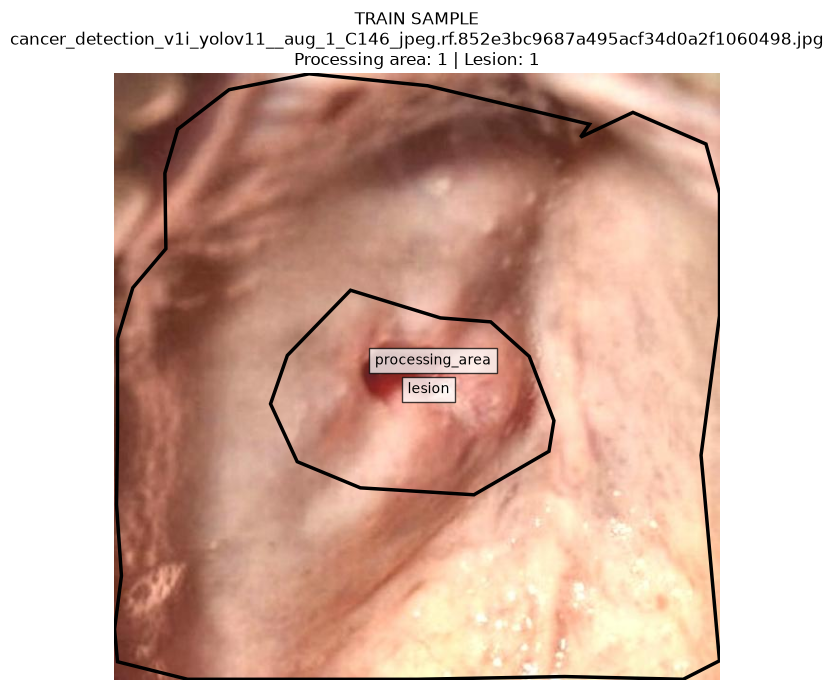

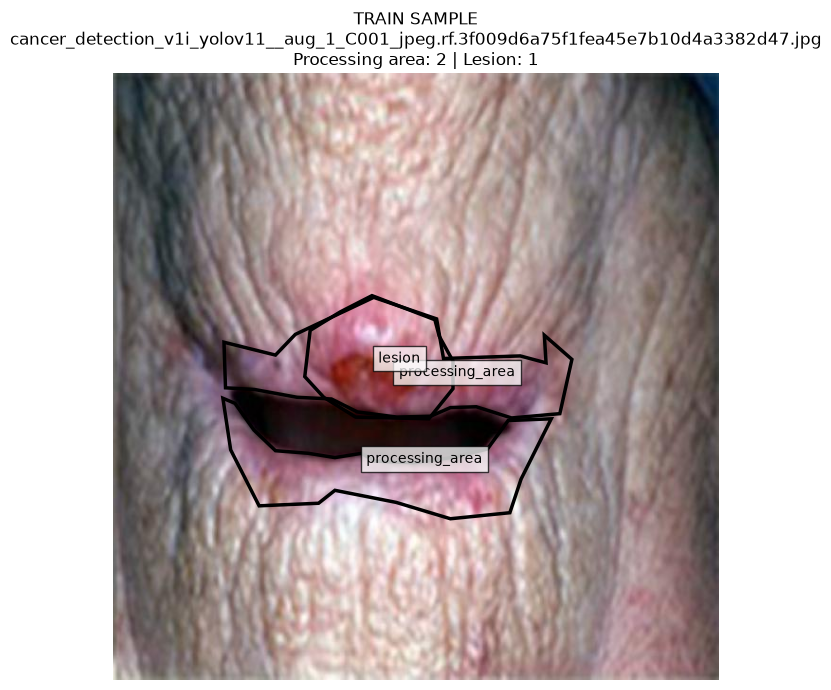

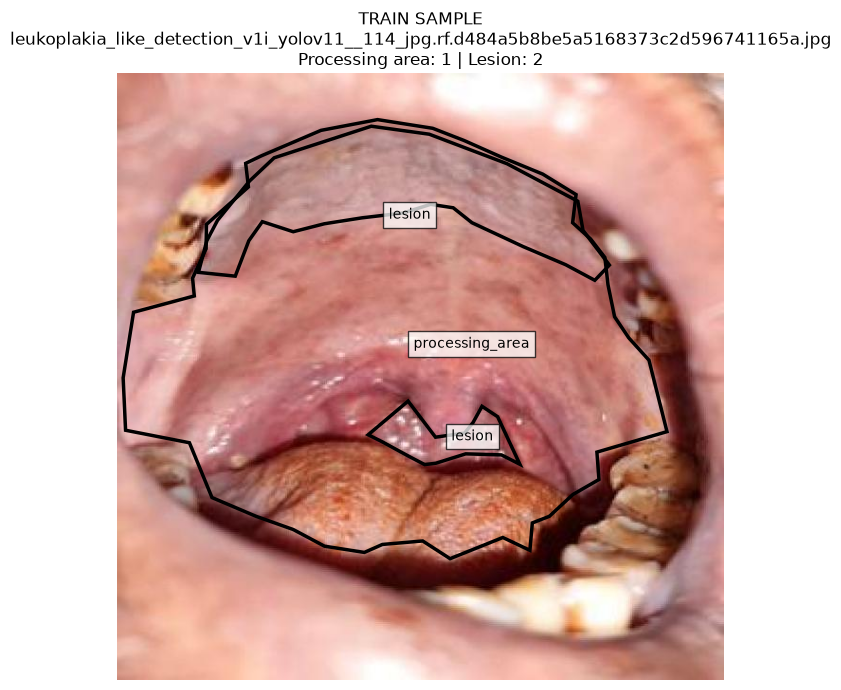

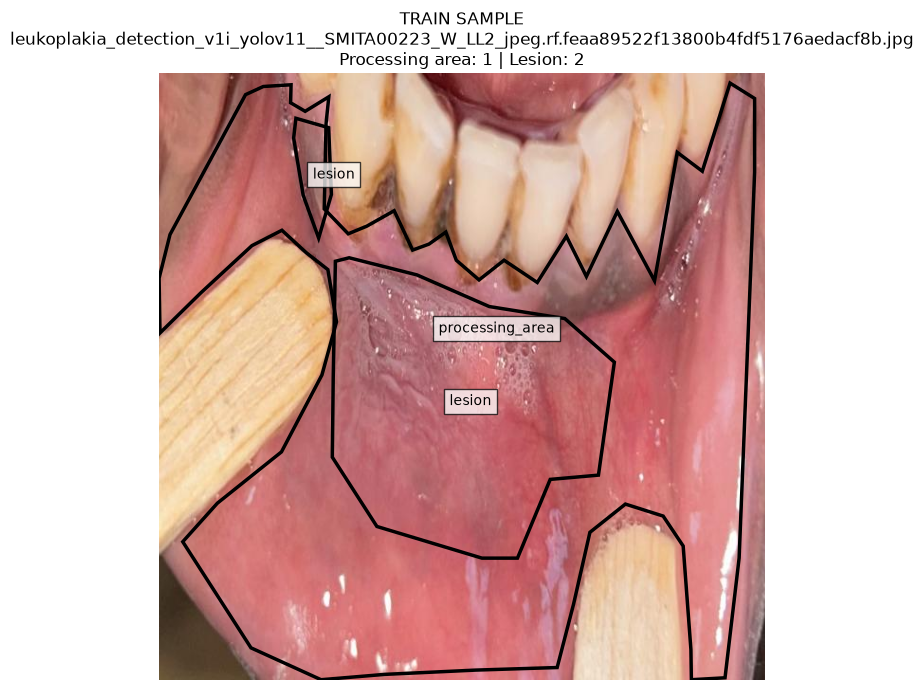

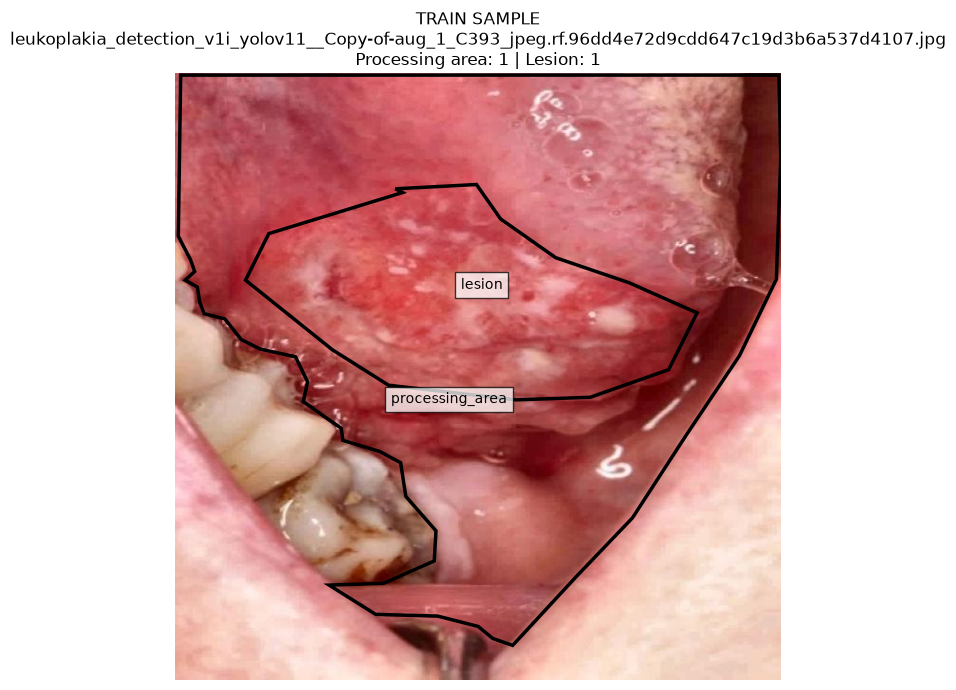

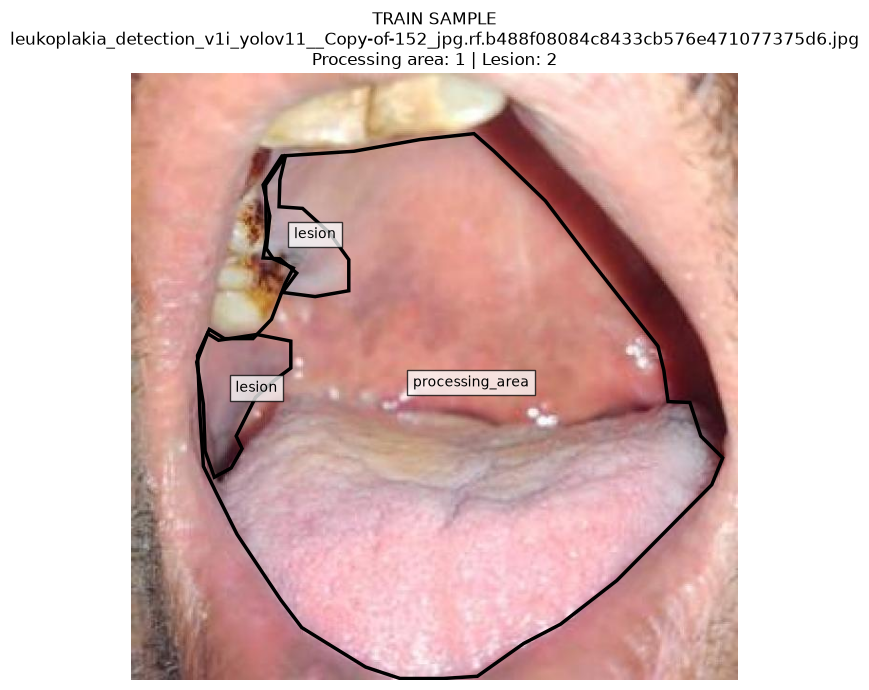

✅ CELL 3 completed.
Visually check polygons, then run CELL 4.


In [ ]:
# ============================================================
# CELL 3: FINAL AUDIT + BALANCE + POLYGON PREVIEW
# ============================================================

from matplotlib.patches import Polygon as MPLPolygon


def get_images(directory):
    """Return supported image files."""

    if not directory.exists():
        return []

    return sorted([
        path
        for path in directory.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])


def get_labels(directory):
    """Return label text files."""

    if not directory.exists():
        return []

    return sorted([
        path
        for path in directory.iterdir()
        if path.is_file()
        and path.suffix.lower() == ".txt"
    ])


def audit_merged_dataset(merged_root):
    """Audit every final image and polygon."""

    valid_rows = []
    invalid_rows = []

    for split in ("train", "valid", "test"):
        images_dir = (
            merged_root /
            split /
            "images"
        )

        labels_dir = (
            merged_root /
            split /
            "labels"
        )

        image_paths = get_images(images_dir)
        label_paths = get_labels(labels_dir)

        print(
            f"{split:<6} | "
            f"images={len(image_paths):<4} | "
            f"labels={len(label_paths):<4}"
        )

        image_stems = {
            path.stem
            for path in image_paths
        }

        label_stems = {
            path.stem
            for path in label_paths
        }

        # Orphan labels
        for orphan_stem in sorted(
            label_stems - image_stems
        ):
            invalid_rows.append({
                "split": split,
                "image": "",
                "label": orphan_stem + ".txt",
                "problem": "Label exists without image"
            })

        for image_path in image_paths:
            label_path = (
                labels_dir /
                f"{image_path.stem}.txt"
            )

            if not label_path.exists():
                invalid_rows.append({
                    "split": split,
                    "image": image_path.name,
                    "label": "",
                    "problem": "Matching label missing"
                })
                continue

            try:
                with Image.open(image_path) as check_image:
                    check_image.verify()

                with open(
                    label_path,
                    "r",
                    encoding="utf-8"
                ) as file:
                    lines = [
                        line.strip()
                        for line in file
                        if line.strip()
                    ]

                if not lines:
                    raise ValueError(
                        "Empty annotation"
                    )

                counts = Counter()
                classes_present = set()

                for line_number, line in enumerate(
                    lines,
                    start=1
                ):
                    tokens = line.split()

                    if len(tokens) < 7:
                        raise ValueError(
                            f"Line {line_number}: invalid polygon"
                        )

                    class_id = int(float(tokens[0]))

                    if class_id not in (0, 1):
                        raise ValueError(
                            f"Line {line_number}: "
                            f"unexpected class {class_id}"
                        )

                    coordinates = [
                        float(value)
                        for value in tokens[1:]
                    ]

                    if len(coordinates) % 2 != 0:
                        raise ValueError(
                            f"Line {line_number}: odd coordinate count"
                        )

                    if len(coordinates) < 6:
                        raise ValueError(
                            f"Line {line_number}: too few points"
                        )

                    if not all(
                        np.isfinite(value)
                        for value in coordinates
                    ):
                        raise ValueError(
                            f"Line {line_number}: NaN/Inf"
                        )

                    if any(
                        value < 0.0 or value > 1.0
                        for value in coordinates
                    ):
                        raise ValueError(
                            f"Line {line_number}: "
                            "coordinate outside [0,1]"
                        )

                    counts[class_id] += 1
                    classes_present.add(class_id)

                # Class 0 = processing area
                if 0 not in classes_present:
                    raise ValueError(
                        "processing_area absent"
                    )

                valid_rows.append({
                    "split": split,
                    "image": image_path.name,
                    "processing_area_instances": counts[0],
                    "lesion_instances": counts[1],
                    "processing_area_present":
                        int(0 in classes_present),
                    "lesion_present":
                        int(1 in classes_present),
                    "total_instances":
                        sum(counts.values())
                })

            except Exception as error:
                invalid_rows.append({
                    "split": split,
                    "image": image_path.name,
                    "label": label_path.name,
                    "problem": str(error)
                })

    return (
        pd.DataFrame(valid_rows),
        pd.DataFrame(invalid_rows)
    )


def remove_invalid_merged_samples(
    invalid_df,
    merged_root
):
    """Remove invalid merged image-label pairs."""

    removed_images = 0

    for _, row in invalid_df.iterrows():
        split = str(row["split"])
        image_name = str(row.get("image", ""))
        label_name = str(row.get("label", ""))

        if image_name:
            image_path = (
                merged_root /
                split /
                "images" /
                image_name
            )

            if image_path.exists():
                image_path.unlink()
                removed_images += 1

        if label_name:
            label_path = (
                merged_root /
                split /
                "labels" /
                label_name
            )

            if label_path.exists():
                label_path.unlink()

    return removed_images


def show_polygon_samples(
    merged_root,
    split="train",
    number_of_images=6,
    seed=42
):
    """Display random polygon annotations."""

    images_dir = (
        merged_root /
        split /
        "images"
    )

    labels_dir = (
        merged_root /
        split /
        "labels"
    )

    image_paths = get_images(images_dir)

    if not image_paths:
        print(f"No images found in {split}.")
        return

    generator = random.Random(seed)

    selected = generator.sample(
        image_paths,
        min(number_of_images, len(image_paths))
    )

    for image_path in selected:
        label_path = (
            labels_dir /
            f"{image_path.stem}.txt"
        )

        image = np.asarray(
            Image.open(image_path).convert("RGB")
        )

        height, width = image.shape[:2]

        figure, axis = plt.subplots(
            figsize=(9, 7)
        )

        axis.imshow(image)

        gum_count = 0
        lesion_count = 0

        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as file:
            for line in file:
                tokens = line.strip().split()

                if not tokens:
                    continue

                class_id = int(float(tokens[0]))

                points = np.asarray(
                    [
                        float(value)
                        for value in tokens[1:]
                    ],
                    dtype=np.float32
                ).reshape(-1, 2)

                pixel_points = points.copy()
                pixel_points[:, 0] *= width
                pixel_points[:, 1] *= height

                polygon = MPLPolygon(
                    pixel_points,
                    closed=True,
                    fill=False,
                    linewidth=2.5
                )

                axis.add_patch(polygon)

                class_name = (
                    FINAL_CLASS_NAMES[class_id]
                )

                center_x = float(
                    pixel_points[:, 0].mean()
                )

                center_y = float(
                    pixel_points[:, 1].mean()
                )

                axis.text(
                    center_x,
                    center_y,
                    class_name,
                    fontsize=10,
                    bbox={
                        "facecolor": "white",
                        "edgecolor": "black",
                        "alpha": 0.75
                    }
                )

                if class_id == 0:
                    gum_count += 1
                else:
                    lesion_count += 1

        axis.set_title(
            f"{split.upper()} SAMPLE\n"
            f"{image_path.name}\n"
            f"Processing area: {gum_count} | "
            f"Lesion: {lesion_count}"
        )

        axis.axis("off")
        plt.tight_layout()
        plt.show()


# ============================================================
# FIRST AUDIT
# ============================================================

print("=" * 92)
print("FINAL MERGED DATASET AUDIT")
print("=" * 92)

audit_df, final_invalid_df = (
    audit_merged_dataset(MERGED_DIR)
)

# Any unexpected invalid files are removed and audited again.
if not final_invalid_df.empty:
    print("\n⚠️ Remaining invalid merged samples:")

    display(final_invalid_df)

    final_invalid_df.to_csv(
        REPORTS_DIR /
        "final_audit_invalid_samples.csv",
        index=False
    )

    removed = remove_invalid_merged_samples(
        final_invalid_df,
        MERGED_DIR
    )

    print(
        f"\nRemoved merged images: {removed}"
    )

    print("\nRunning audit again...")

    audit_df, second_invalid_df = (
        audit_merged_dataset(MERGED_DIR)
    )

    if not second_invalid_df.empty:
        display(second_invalid_df)

        raise RuntimeError(
            "Merged dataset still contains invalid samples."
        )

if audit_df.empty:
    raise RuntimeError(
        "No valid merged images available."
    )

# ============================================================
# FINAL SUMMARY
# ============================================================

summary_rows = []

for split in ("train", "valid", "test"):
    subset = audit_df[
        audit_df["split"] == split
    ]

    if subset.empty:
        summary_rows.append({
            "split": split,
            "total_images": 0,
            "processing_area_images": 0,
            "lesion_positive_images": 0,
            "lesion_negative_images": 0,
            "processing_area_polygons": 0,
            "lesion_polygons": 0,
            "imbalance_ratio": None
        })
        continue

    processing_count = int(
        subset["processing_area_instances"].sum()
    )

    lesion_count = int(
        subset["lesion_instances"].sum()
    )

    if processing_count > 0 and lesion_count > 0:
        ratio = (
            max(processing_count, lesion_count)
            / min(processing_count, lesion_count)
        )
    else:
        ratio = None

    summary_rows.append({
        "split": split,
        "total_images": len(subset),

        "processing_area_images": int(
            subset["processing_area_present"].sum()
        ),

        "lesion_positive_images": int(
            subset["lesion_present"].sum()
        ),

        "lesion_negative_images": int(
            (subset["lesion_present"] == 0).sum()
        ),

        "processing_area_polygons":
            processing_count,

        "lesion_polygons":
            lesion_count,

        "imbalance_ratio": (
            round(ratio, 3)
            if ratio is not None
            else None
        )
    })

summary_df = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 100)
print("FINAL TRAIN / VALID / TEST SUMMARY")
print("=" * 100)

display(summary_df)

# ============================================================
# REQUIRED CHECKS
# ============================================================

train_images = int(
    summary_df.loc[
        summary_df["split"] == "train",
        "total_images"
    ].iloc[0]
)

valid_images = int(
    summary_df.loc[
        summary_df["split"] == "valid",
        "total_images"
    ].iloc[0]
)

test_images = int(
    summary_df.loc[
        summary_df["split"] == "test",
        "total_images"
    ].iloc[0]
)

if train_images == 0:
    raise RuntimeError(
        "Training split is empty."
    )

if valid_images == 0:
    raise RuntimeError(
        "Validation split is empty."
    )

if test_images == 0:
    print(
        "⚠️ Test split is empty; final evaluation "
        "will use valid split."
    )

# Check both classes exist in training.
train_subset = audit_df[
    audit_df["split"] == "train"
]

if int(train_subset["processing_area_instances"].sum()) == 0:
    raise RuntimeError(
        "No processing_area annotations in training."
    )

if int(train_subset["lesion_instances"].sum()) == 0:
    raise RuntimeError(
        "No lesion annotations in training."
    )

# Verify YAML
with open(
    MERGED_YAML_PATH,
    "r",
    encoding="utf-8"
) as file:
    checked_yaml = yaml.safe_load(file)

assert int(checked_yaml["nc"]) == 2

names = checked_yaml["names"]

if isinstance(names, list):
    assert names == [
        "processing_area",
        "lesion"
    ]
else:
    assert str(names[0]) == "processing_area"
    assert str(names[1]) == "lesion"

print("\nFinal class order:")
print("  Class 0 → processing_area")
print("  Class 1 → lesion")

train_ratio = summary_df.loc[
    summary_df["split"] == "train",
    "imbalance_ratio"
].iloc[0]

if pd.notna(train_ratio):
    print(
        f"\nTraining polygon imbalance ratio: "
        f"{float(train_ratio):.3f}:1"
    )

    if float(train_ratio) <= 1.5:
        print("Balance assessment: Mild imbalance")
    elif float(train_ratio) <= 2.0:
        print("Balance assessment: Acceptable imbalance")
    elif float(train_ratio) <= 3.0:
        print("Balance assessment: Moderate imbalance")
    else:
        print("Balance assessment: High imbalance")

print(
    "\nNaive image duplication is not used because each "
    "lesion-positive image also contains processing-area polygons. "
    "Duplicating it would increase both class counts and may cause "
    "overfitting."
)

# ============================================================
# VISUAL PREVIEW
# ============================================================

print("\nRandom polygon previews:")

show_polygon_samples(
    merged_root=MERGED_DIR,
    split="train",
    number_of_images=6,
    seed=SEED
)

print("=" * 92)
print("✅ CELL 3 completed.")
print("Visually check polygons, then run CELL 4.")
print("=" * 92)

ORALSCAN YOLO26-M SEGMENTATION TRAINING
Checkpoint             : yolo26m-seg.pt
Dataset YAML           : /content/oralscan_training_workspace/merged_dataset/data.yaml
Class 0                : processing_area
Class 1                : lesion
Image size             : 640
Batch size             : 16
Maximum epochs         : 300
Early-stop patience    : 40
Optimizer              : AdamW
Cosine LR              : True
Mixed precision        : True
Final model path       : /content/best_oralscan_yolo26m_seg.pt
Training GPU           : NVIDIA A100-SXM4-40GB
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/oralsca

,Metric,Value
0,Mask Precision,0.6125
1,Mask Recall,0.5271
2,Mask mAP@0.50,0.4683
3,Mask mAP@0.50:0.95,0.2081
4,Box Precision,0.7273
5,Box Recall,0.7124
6,Box mAP@0.50,0.7095
7,Box mAP@0.50:0.95,0.4493



PER-CLASS RESULTS


,Class ID,Class,Mask mAP@0.50:0.95,Box mAP@0.50:0.95
0,0,processing_area,0.2527,0.7045
1,1,lesion,0.1636,0.1941



TRAINING GRAPHS

results.png


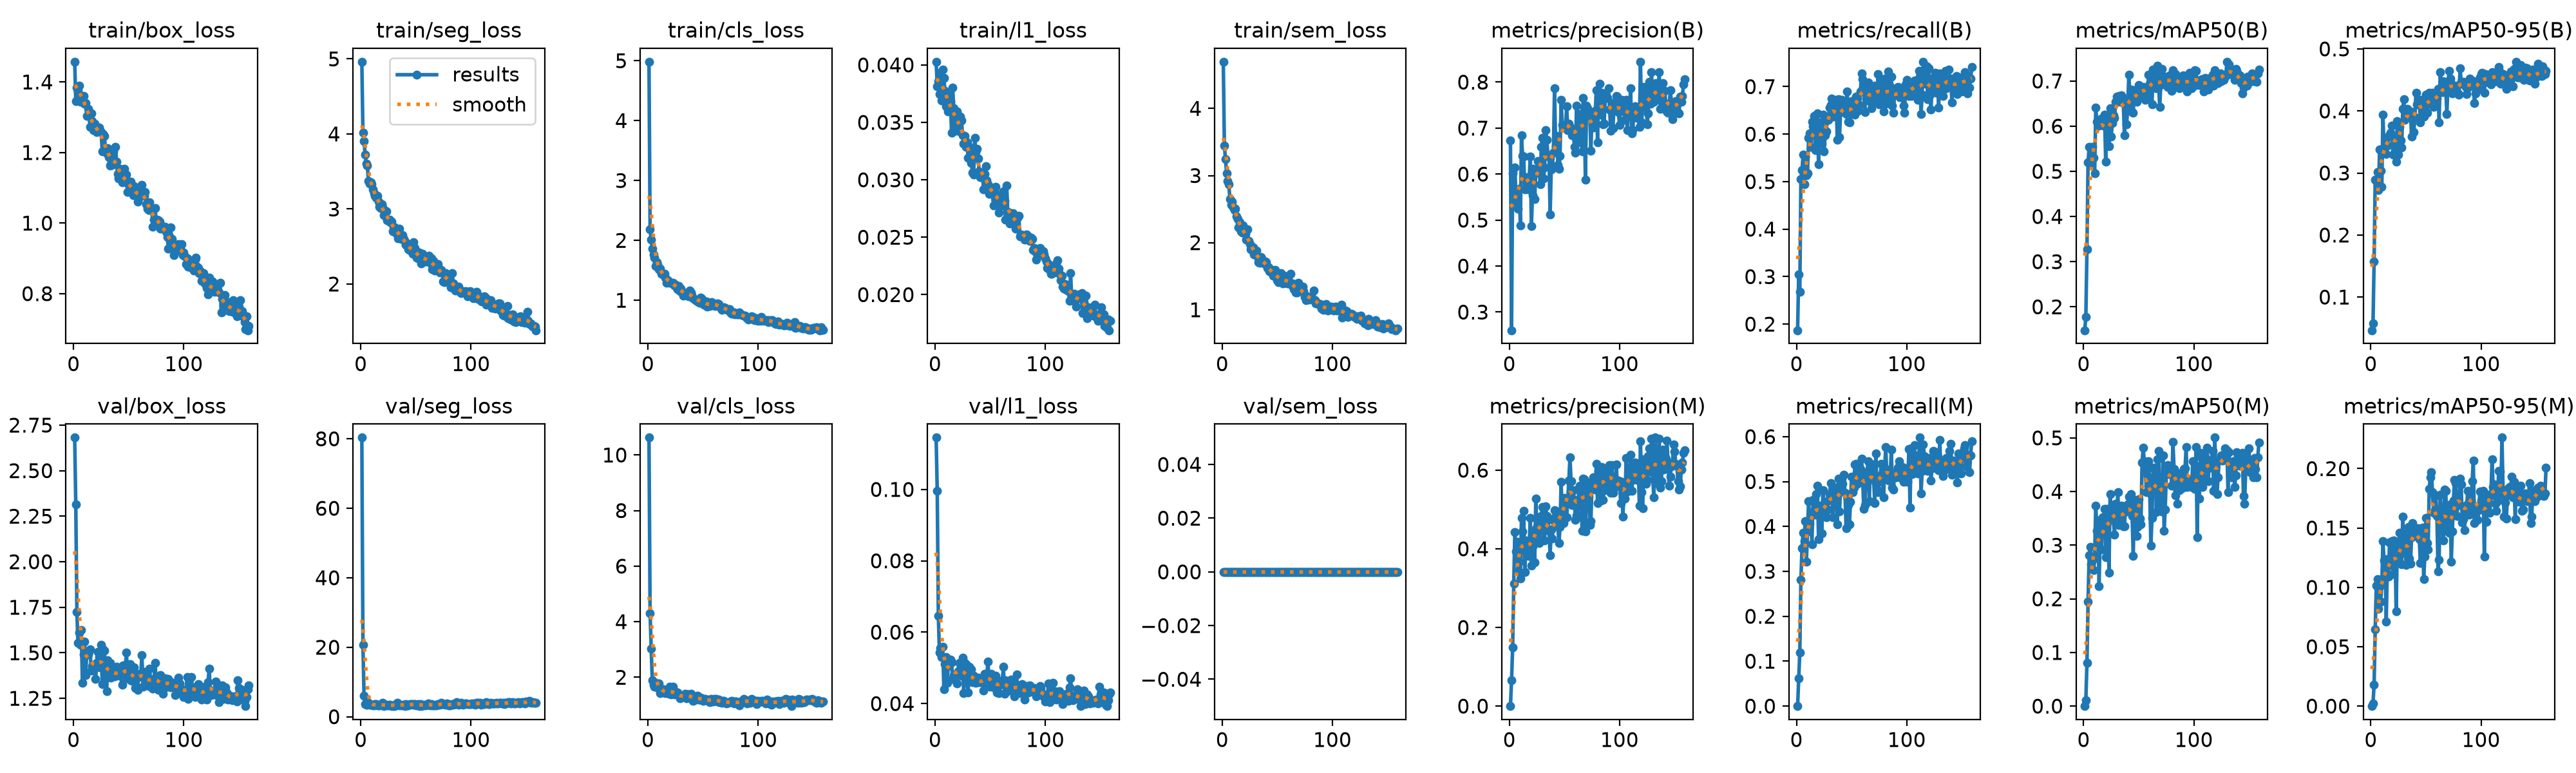


confusion_matrix_normalized.png


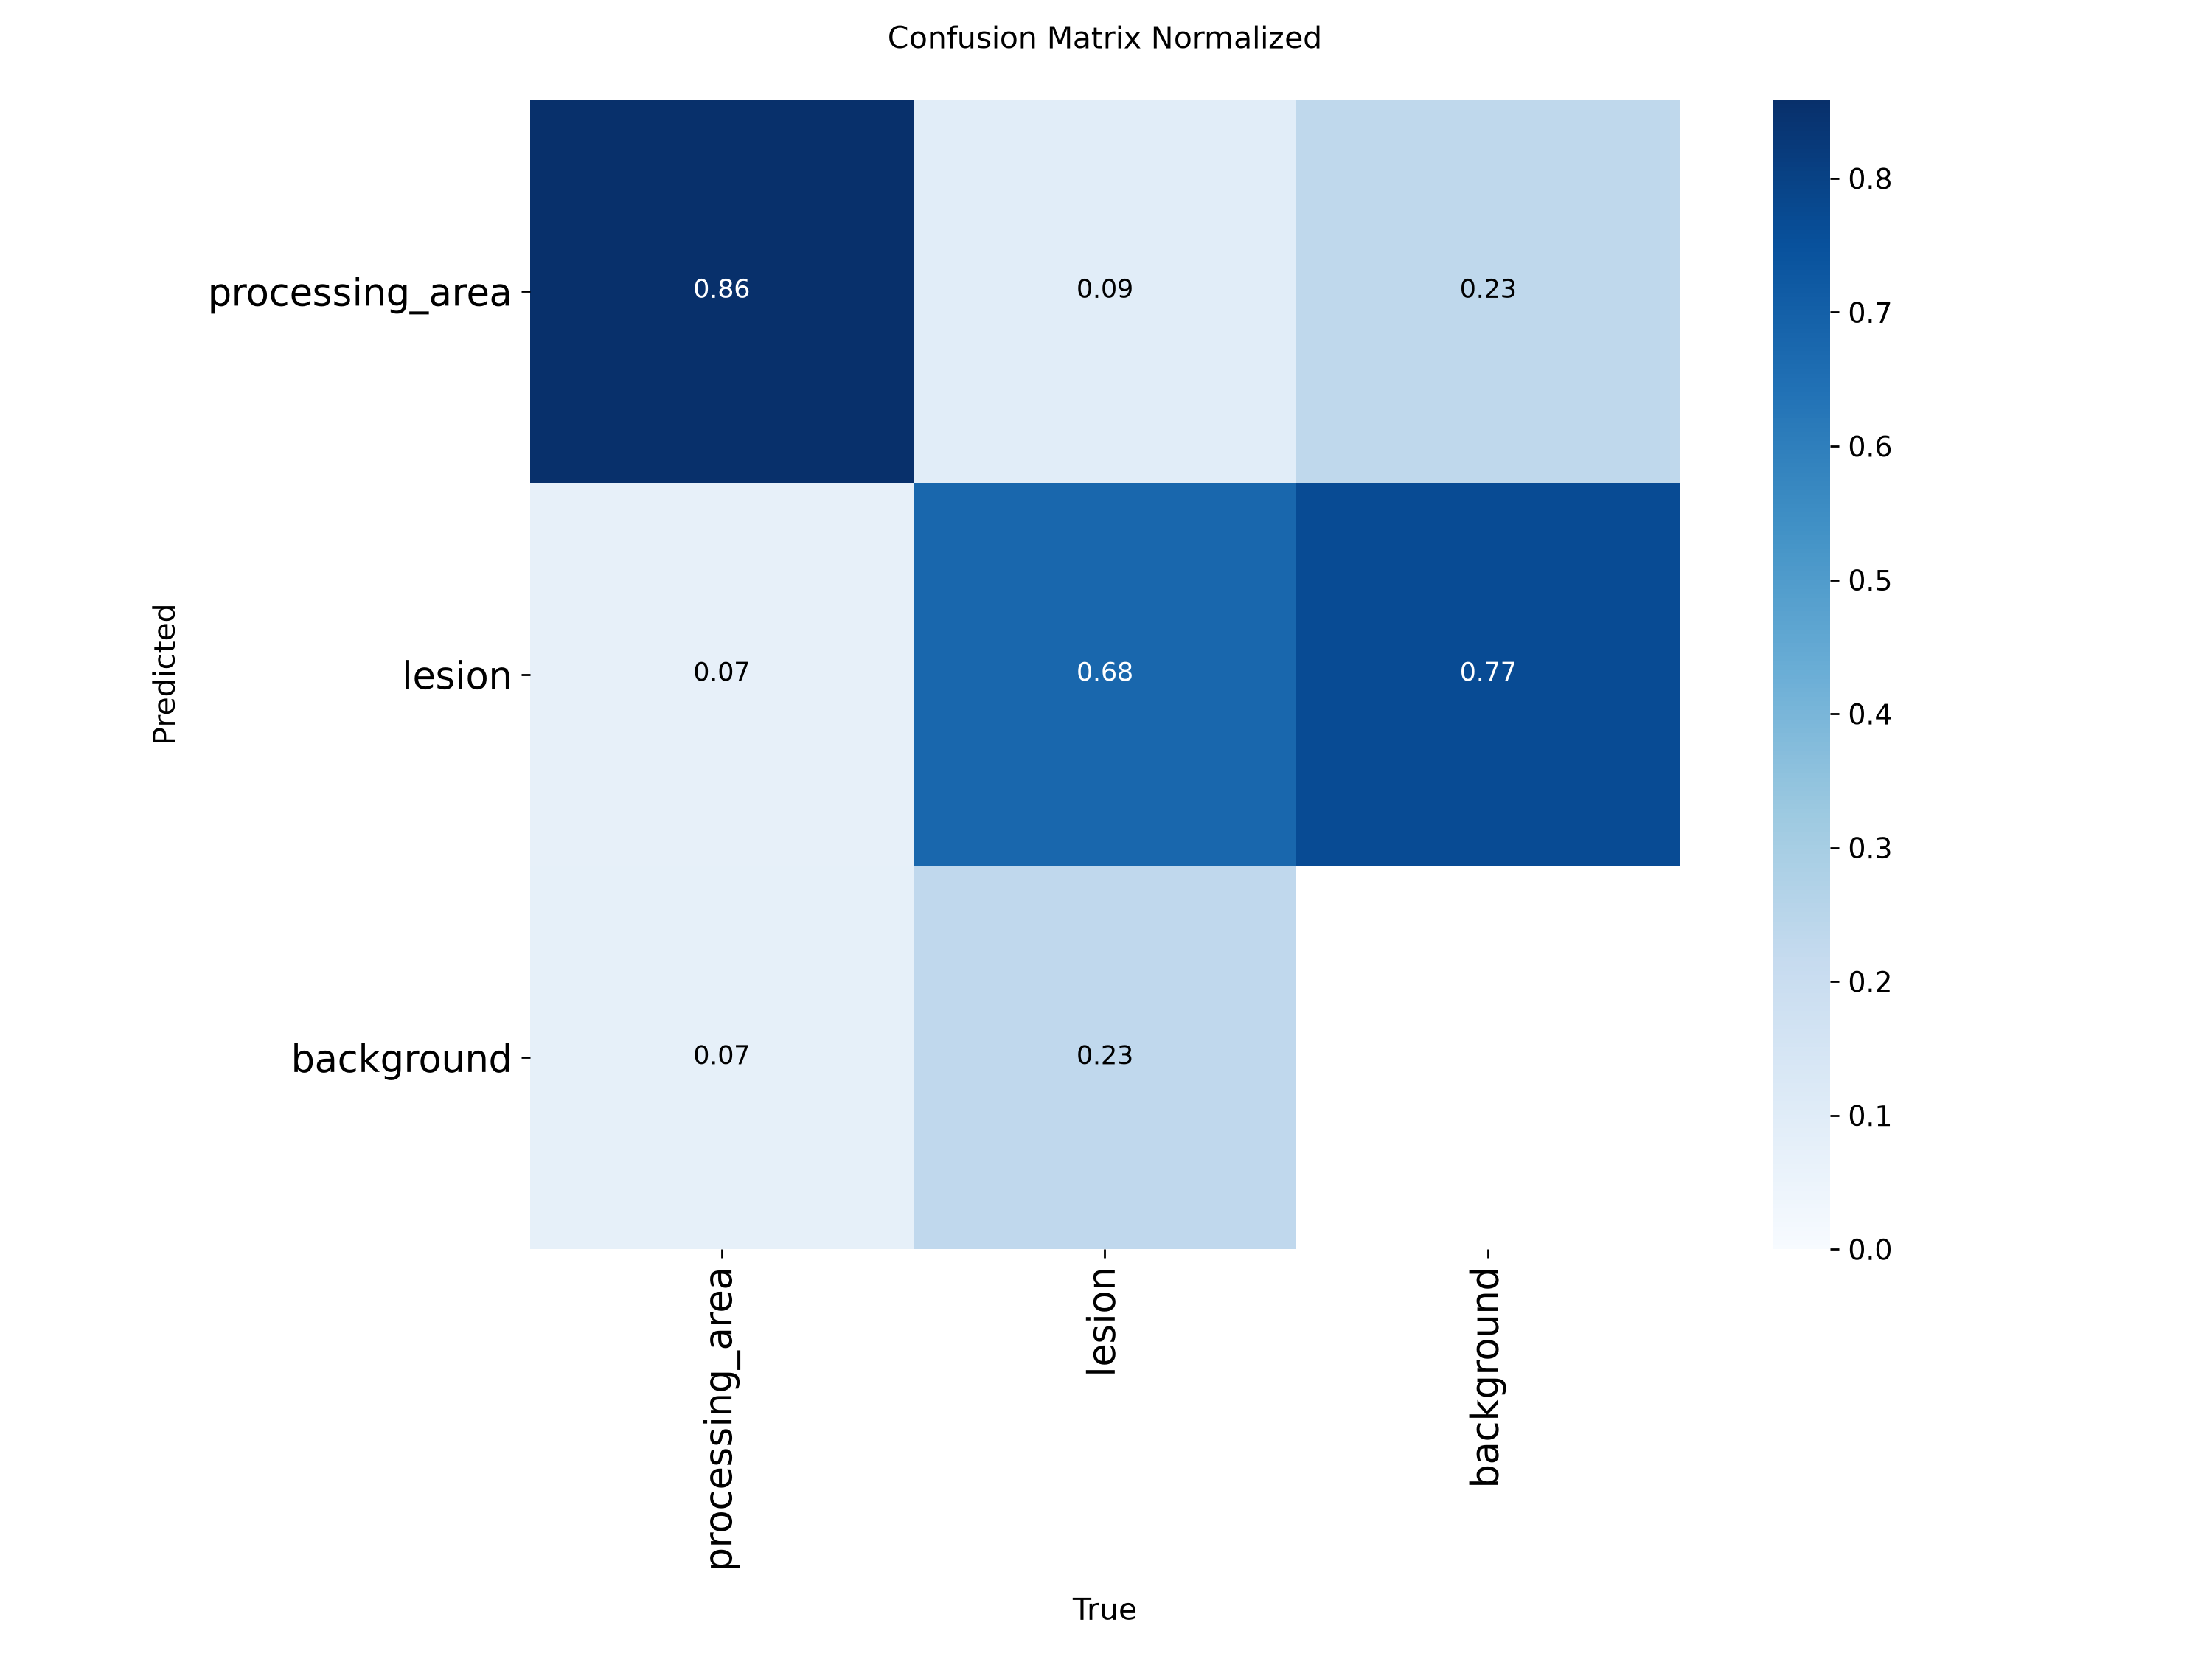


MaskPR_curve.png


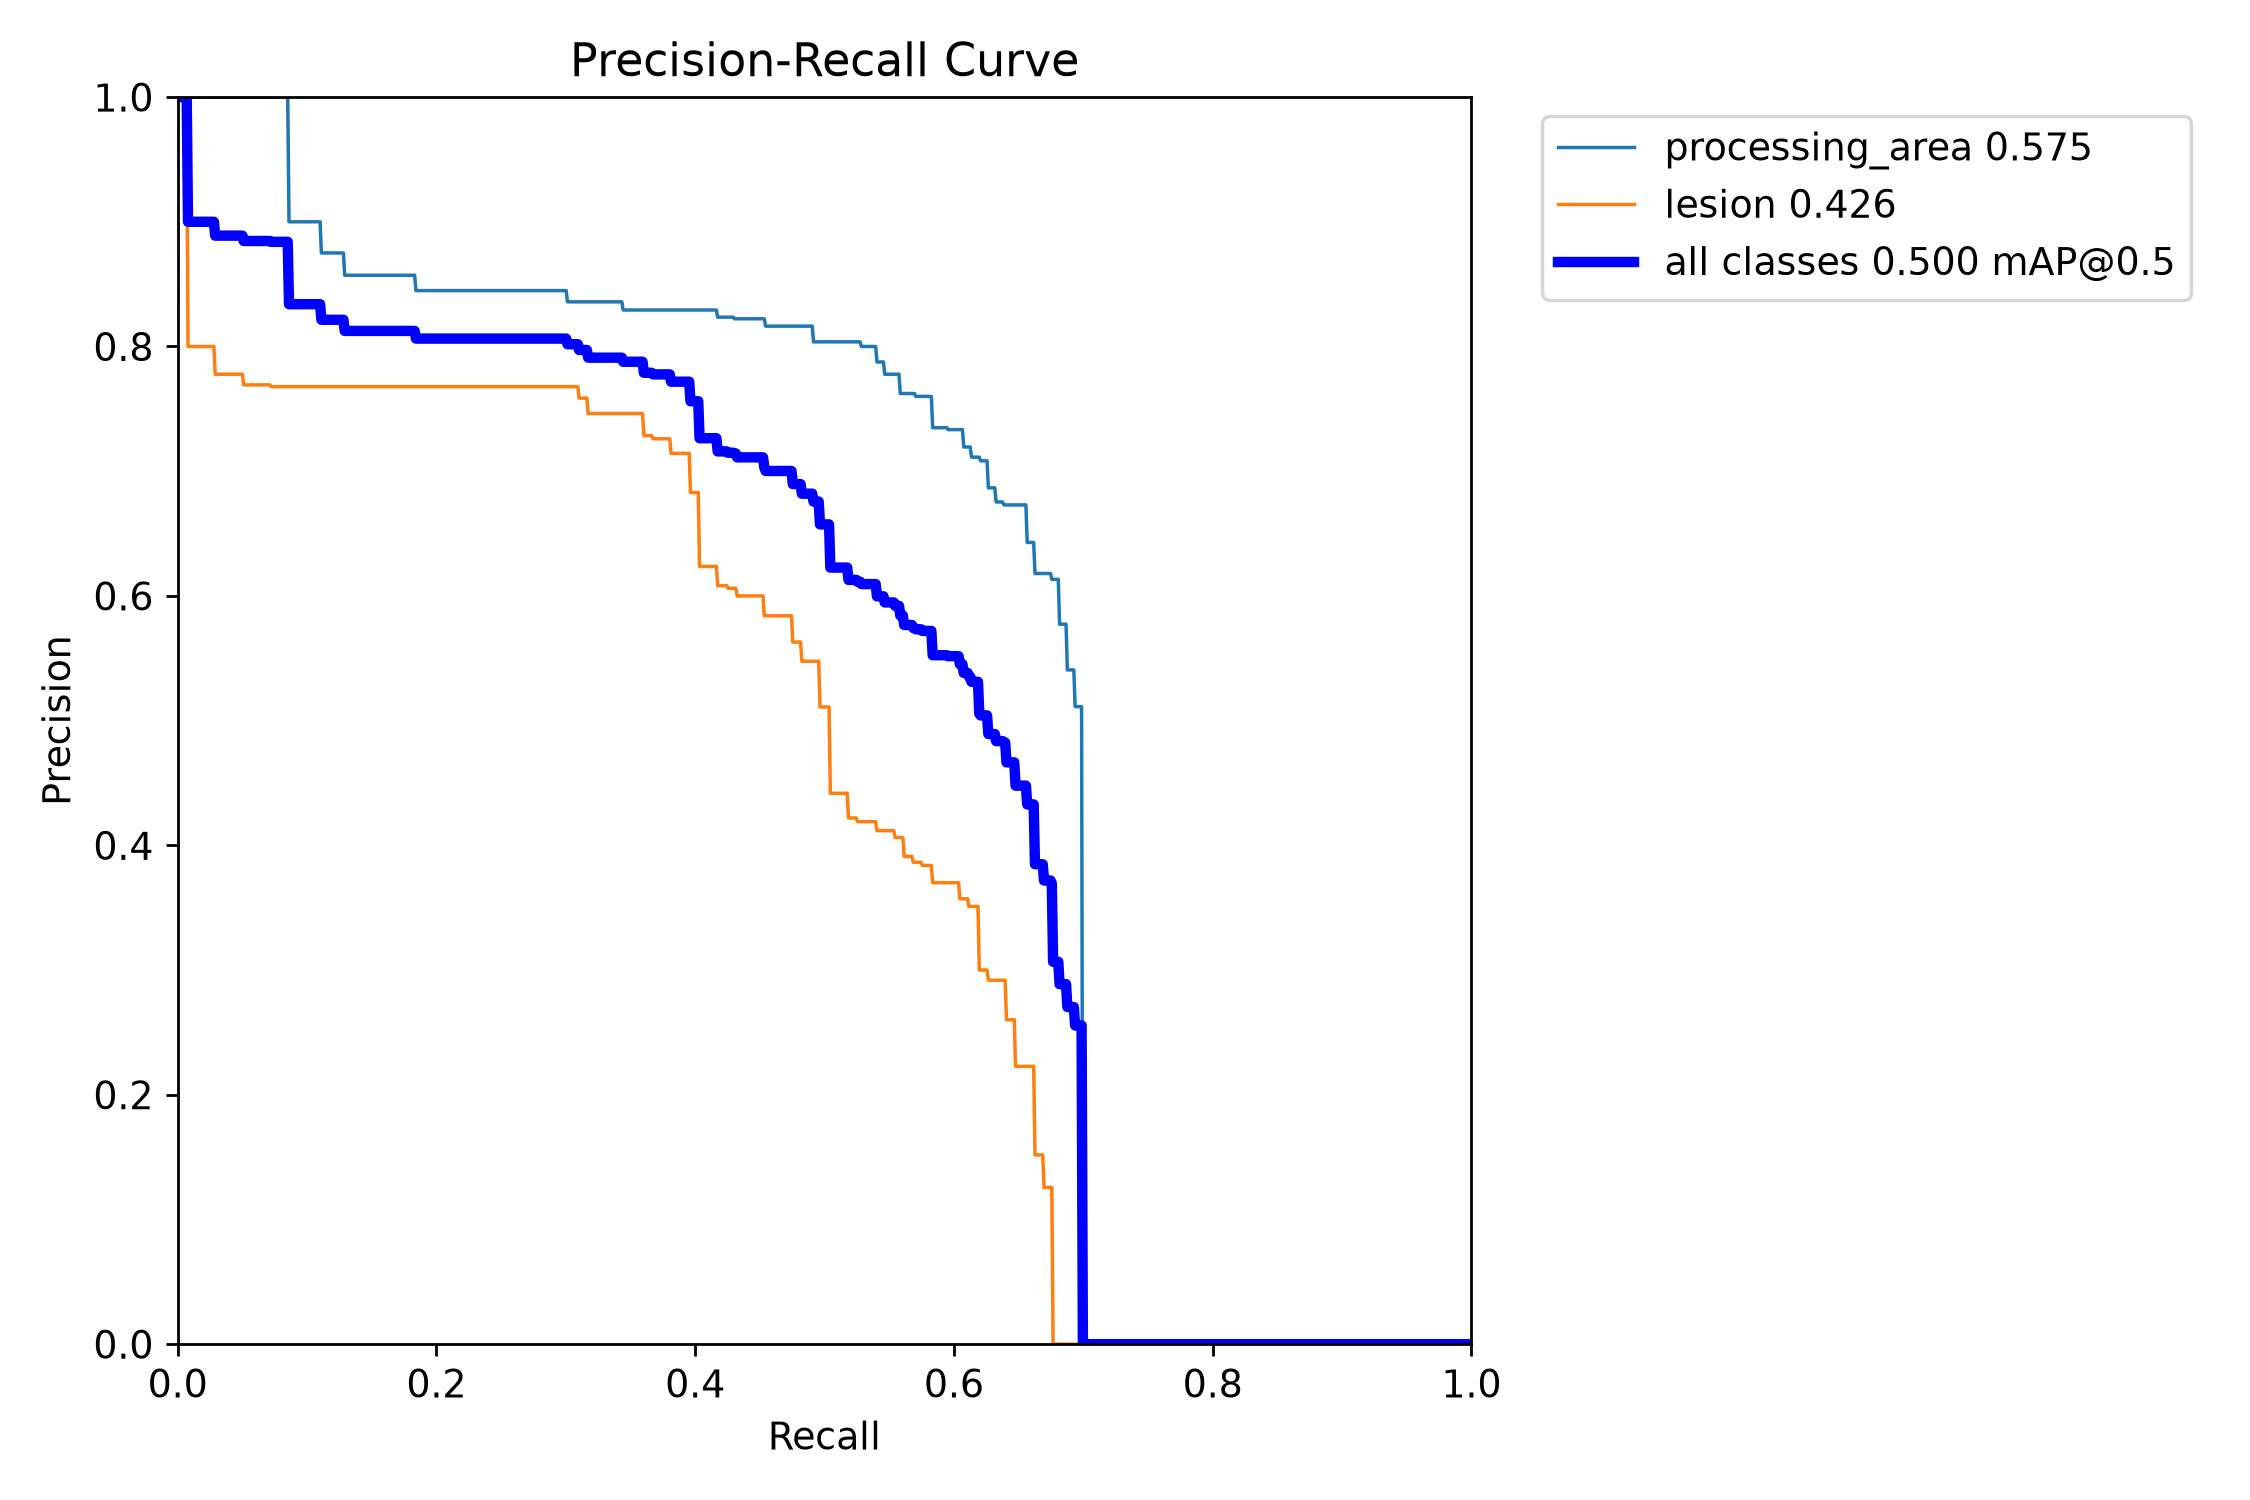


MaskF1_curve.png


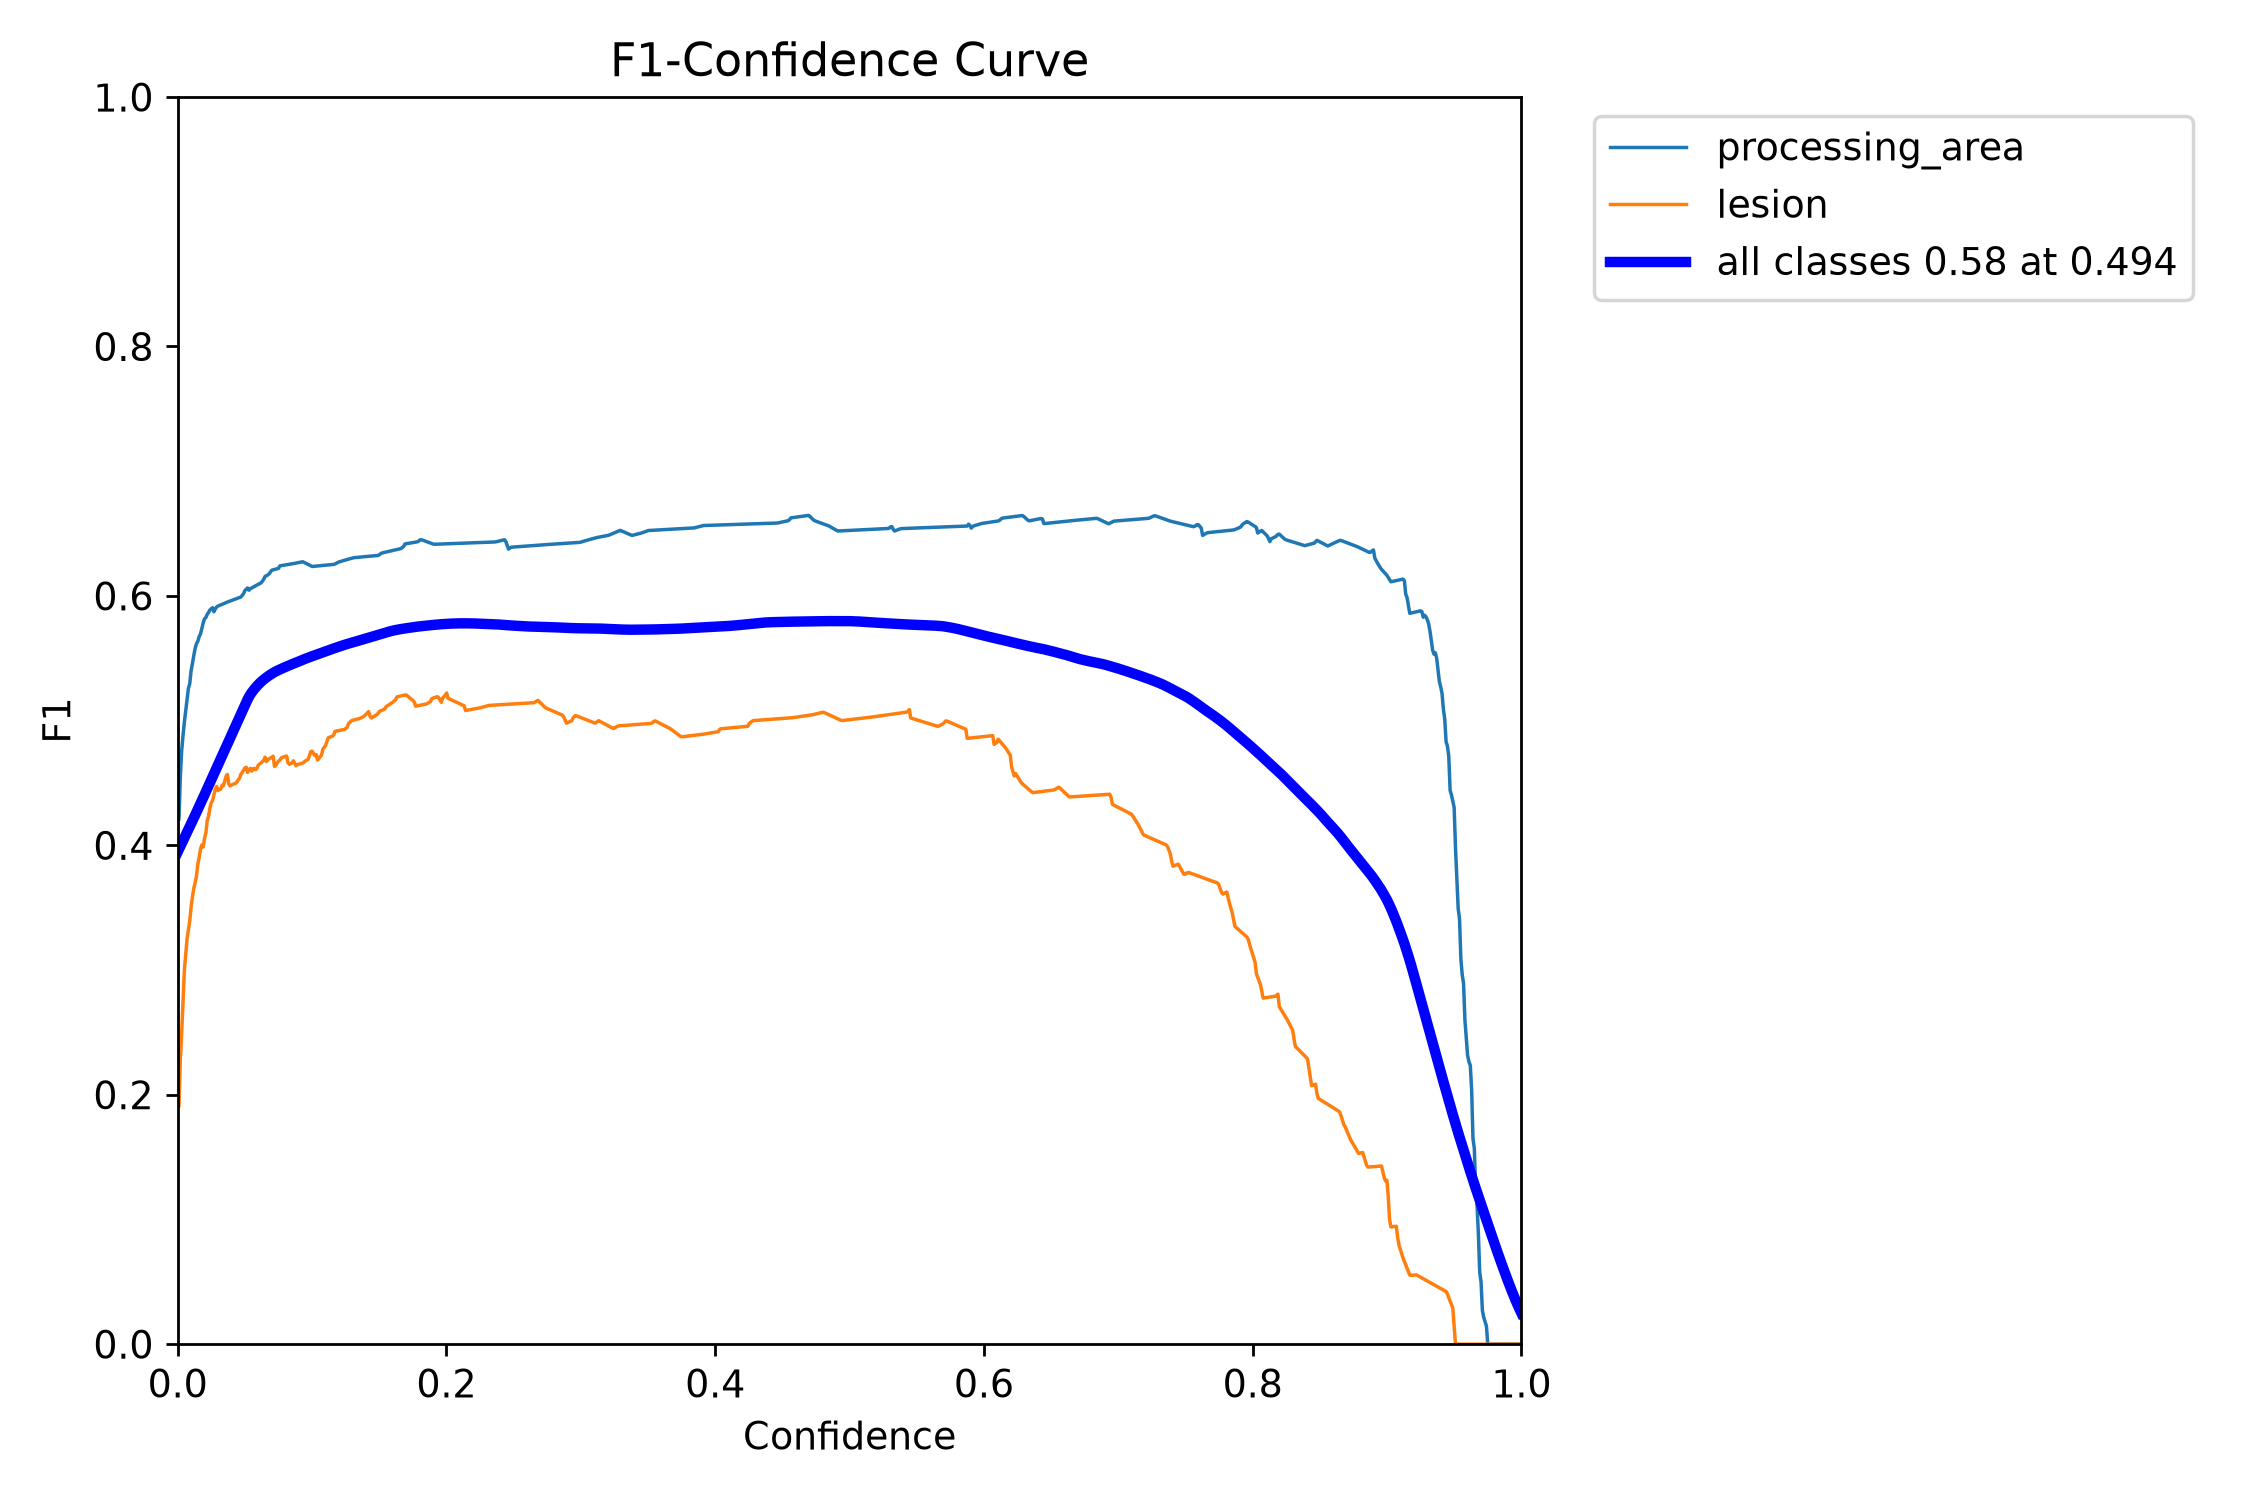


confusion_matrix_normalized.png


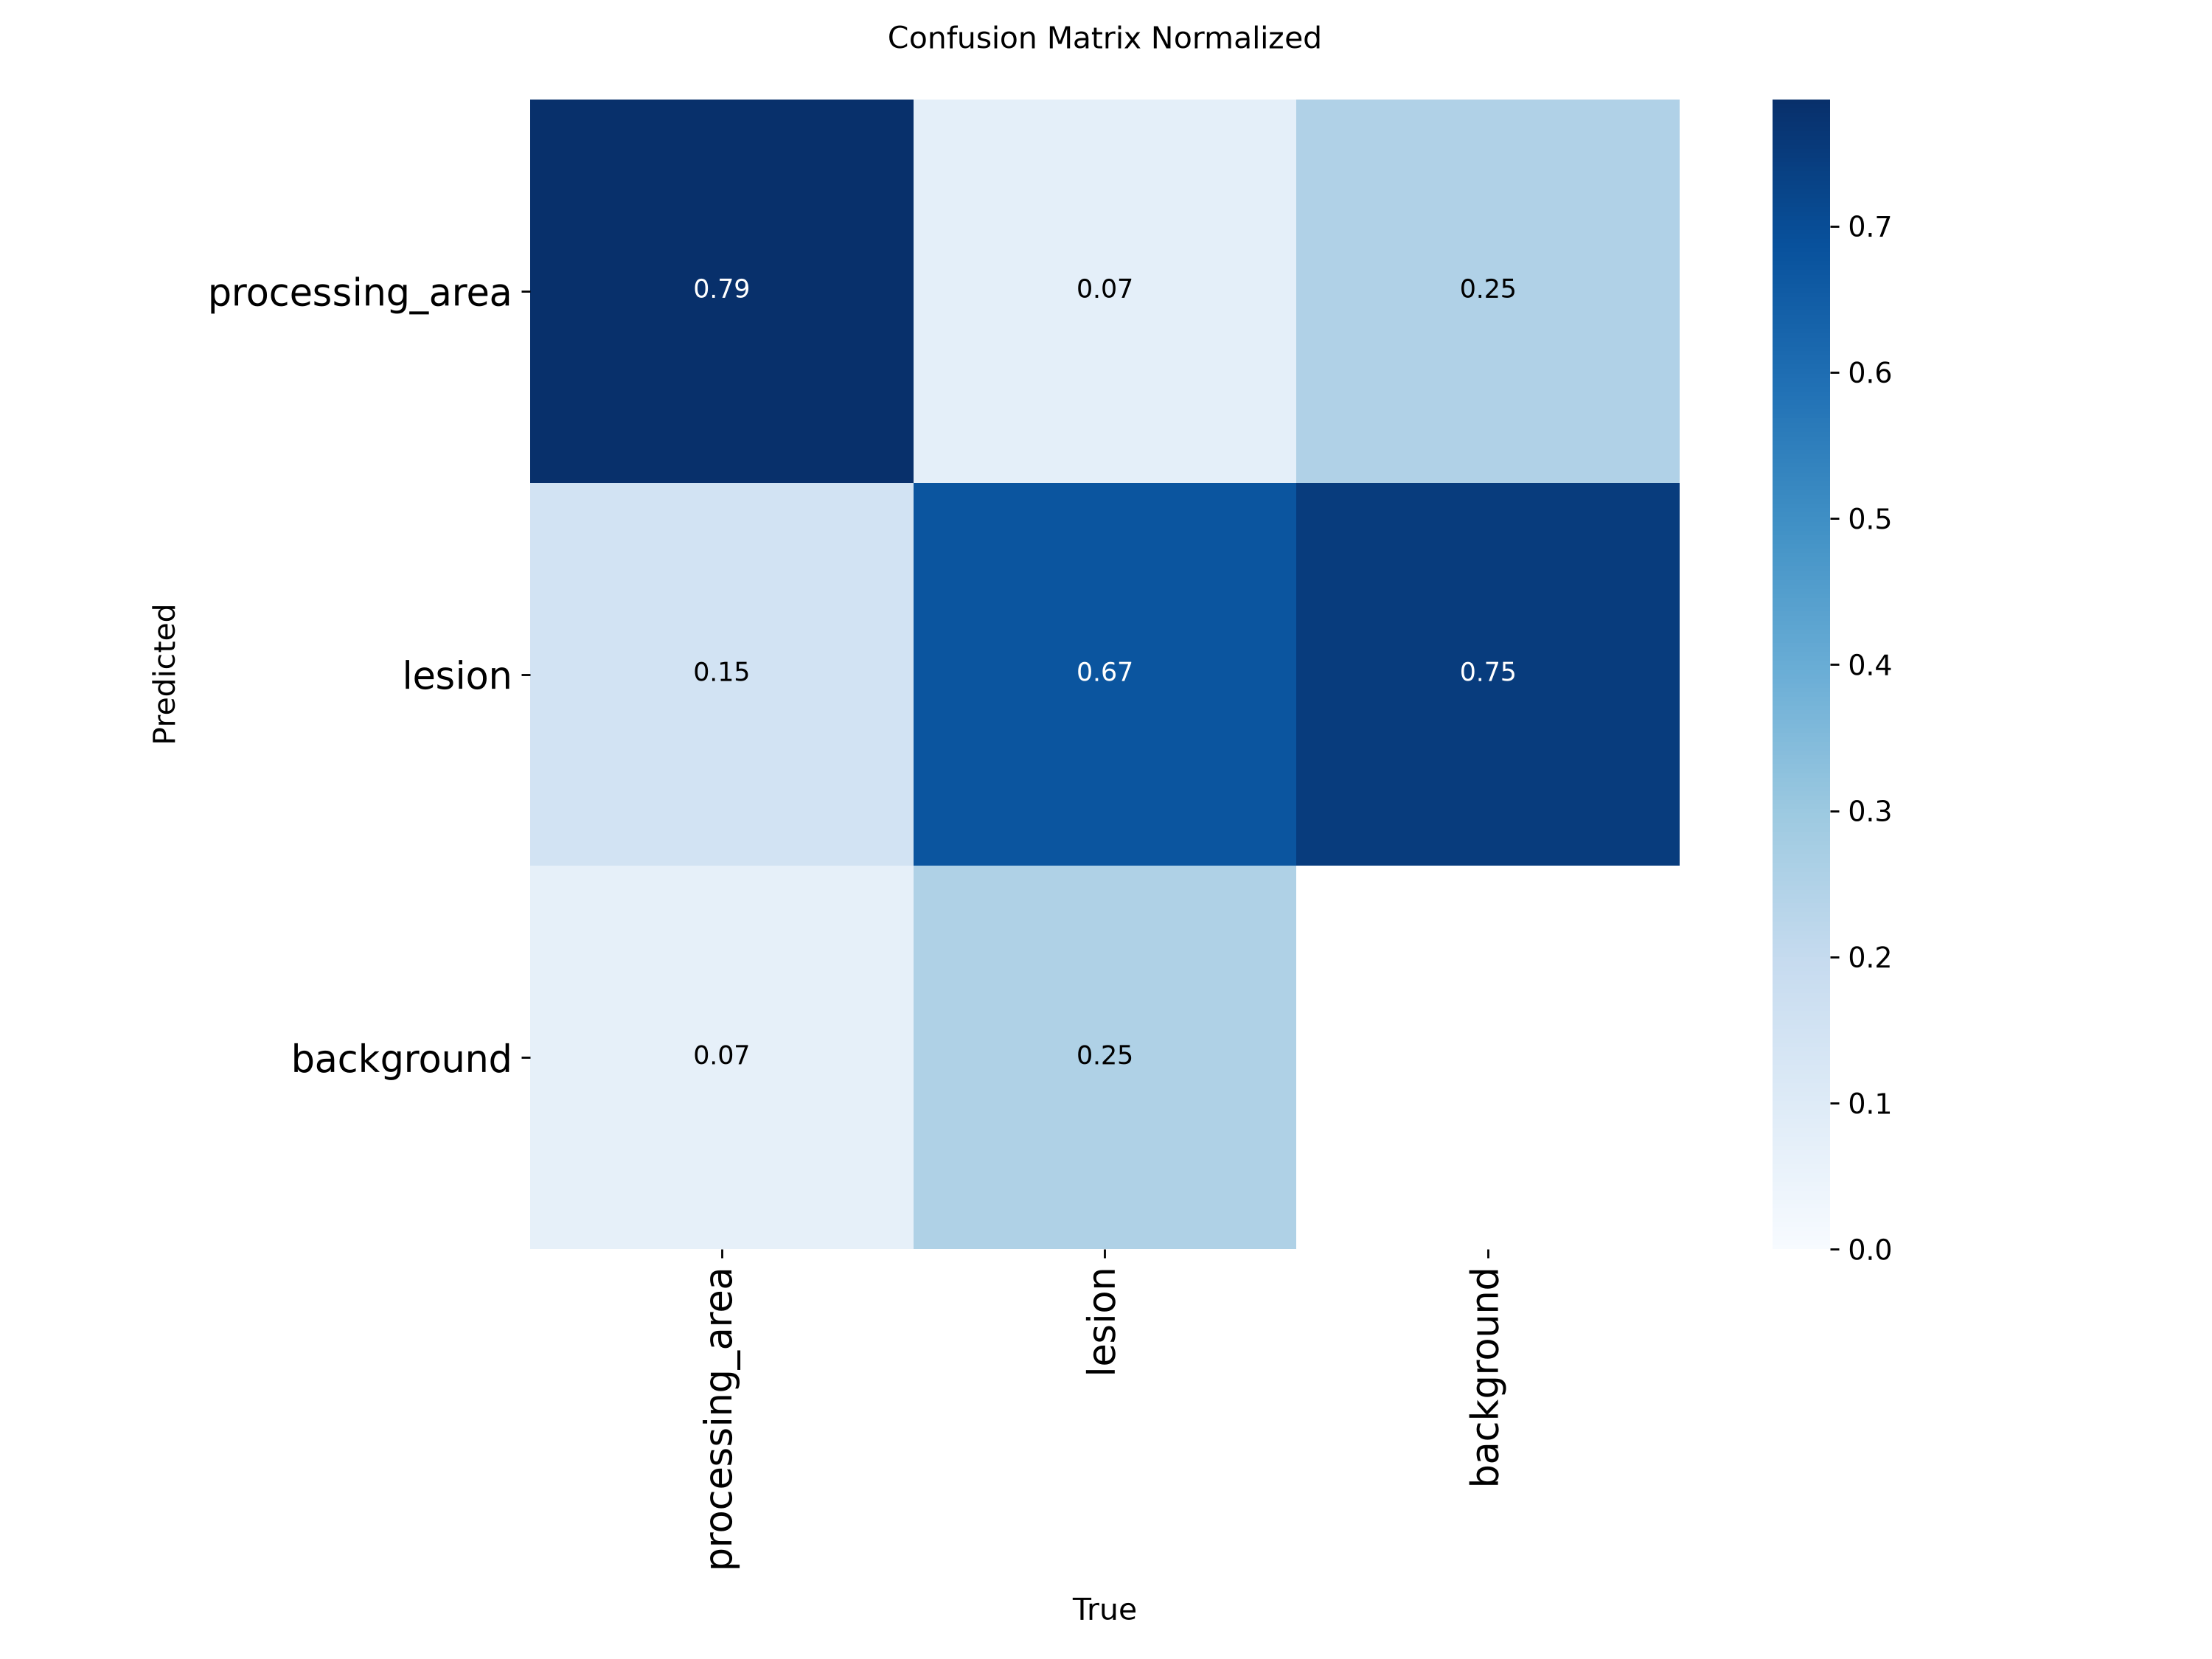


ORALSCAN TRAINING COMPLETED
Final model           : /content/best_oralscan_yolo26m_seg.pt
Model size            : 51.98 MB
Class mapping         : {0: 'processing_area', 1: 'lesion'}
Training time         : 38.06 minutes
Evaluation split      : test
Mask Precision        : 0.6125
Mask Recall           : 0.5271
Mask mAP@0.50         : 0.4683
Mask mAP@0.50:0.95    : 0.2081
Metrics JSON          : /content/oralscan_training_workspace/reports/final_training_metrics.json
------------------------------------------------------------------------------------------------
✅ Final file is best.pt, not last.pt.
✅ Early stopping was active.
✅ Class 0 = processing_area.
✅ Class 1 = lesion.
✅ Model is ready for fixed 4-output inference.


In [ ]:
# ============================================================
# CELL 4: TRAIN + EARLY STOPPING + FINAL VALIDATION
# ============================================================


def safe_float(value):
    """Safely convert metric to float."""

    if value is None:
        return None

    try:
        return float(value)
    except (TypeError, ValueError):
        return None


def display_metric(value):
    """Readable metric formatting."""

    if value is None:
        return "Not available"

    try:
        if np.isnan(value):
            return "Not available"
    except TypeError:
        pass

    return f"{float(value):.4f}"


# ============================================================
# PRE-TRAINING CHECKS
# ============================================================

if not MERGED_YAML_PATH.exists():
    raise FileNotFoundError(
        "Merged data.yaml not found. Run Cells 1–3."
    )

if RUNS_DIR.exists():
    shutil.rmtree(RUNS_DIR)

RUNS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

RUN_NAME = "oralscan_yolo26m_seg"

print("=" * 96)
print("ORALSCAN YOLO26-M SEGMENTATION TRAINING")
print("=" * 96)

print(f"Checkpoint             : {MODEL_CHECKPOINT}")
print(f"Dataset YAML           : {MERGED_YAML_PATH}")
print(f"Class 0                : processing_area")
print(f"Class 1                : lesion")
print(f"Image size             : {IMAGE_SIZE}")
print(f"Batch size             : {BATCH_SIZE}")
print(f"Maximum epochs         : {MAX_EPOCHS}")
print(f"Early-stop patience    : {EARLY_STOPPING_PATIENCE}")
print(f"Optimizer              : AdamW")
print(f"Cosine LR              : True")
print(f"Mixed precision        : True")
print(f"Final model path       : {SAVE_MODEL_PATH}")

if torch.cuda.is_available():
    print(
        f"Training GPU           : "
        f"{torch.cuda.get_device_name(0)}"
    )
else:
    print("Training device        : CPU")

print("=" * 96)

# ============================================================
# LOAD PRETRAINED MODEL
# ============================================================

model = YOLO(
    MODEL_CHECKPOINT
)

training_start = time.time()

# ============================================================
# TRAIN
# ============================================================

try:
    training_result = model.train(
        data=str(MERGED_YAML_PATH),
        project=str(RUNS_DIR),
        name=RUN_NAME,
        **TRAIN_ARGUMENTS
    )

except RuntimeError as error:
    if "out of memory" in str(error).lower():
        raise RuntimeError(
            "\nCUDA OUT OF MEMORY\n"
            "Cell 1 mein BATCH_SIZE = 16 ko "
            "BATCH_SIZE = 8 karein, phir Cell 4 rerun karein."
        ) from error

    raise

training_minutes = (
    time.time() - training_start
) / 60.0

# ============================================================
# LOCATE BEST CHECKPOINT
# ============================================================

RUN_DIRECTORY = (
    RUNS_DIR /
    RUN_NAME
)

BEST_CHECKPOINT = (
    RUN_DIRECTORY /
    "weights" /
    "best.pt"
)

LAST_CHECKPOINT = (
    RUN_DIRECTORY /
    "weights" /
    "last.pt"
)

if not BEST_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"best.pt was not found:\n{BEST_CHECKPOINT}"
    )

print("\n" + "=" * 96)
print("TRAINING FINISHED")
print("=" * 96)

print(
    f"Training duration      : "
    f"{training_minutes:.2f} minutes"
)

print(f"Best checkpoint        : {BEST_CHECKPOINT}")
print(f"Last checkpoint        : {LAST_CHECKPOINT}")

# ============================================================
# LOAD AND VERIFY BEST MODEL
# ============================================================

best_model = YOLO(
    str(BEST_CHECKPOINT)
)

model_names = {
    int(class_id): str(class_name)
    for class_id, class_name
    in best_model.names.items()
}

expected_names = {
    0: "processing_area",
    1: "lesion"
}

if model_names != expected_names:
    raise RuntimeError(
        "Trained model class order is incorrect.\n"
        f"Expected: {expected_names}\n"
        f"Found:    {model_names}"
    )

print(f"Verified classes       : {model_names}")

# ============================================================
# SELECT FINAL EVALUATION SPLIT
# ============================================================

test_image_count = len(
    get_images(
        MERGED_DIR /
        "test" /
        "images"
    )
)

evaluation_split = (
    "test"
    if test_image_count > 0
    else "val"
)

print("\n" + "=" * 96)
print(
    f"FINAL EVALUATION SPLIT: "
    f"{evaluation_split.upper()}"
)
print("=" * 96)

# ============================================================
# FINAL VALIDATION
# ============================================================

evaluation_results = best_model.val(
    data=str(MERGED_YAML_PATH),
    split=evaluation_split,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=TRAIN_ARGUMENTS["device"],
    workers=WORKERS,
    conf=VAL_CONFIDENCE,
    iou=VAL_IOU,
    plots=True,
    verbose=True,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}_final_evaluation",
    exist_ok=True
)

# ============================================================
# OVERALL METRICS
# ============================================================

metrics = {
    "Mask Precision": safe_float(
        getattr(evaluation_results.seg, "mp", None)
    ),

    "Mask Recall": safe_float(
        getattr(evaluation_results.seg, "mr", None)
    ),

    "Mask mAP@0.50": safe_float(
        getattr(evaluation_results.seg, "map50", None)
    ),

    "Mask mAP@0.50:0.95": safe_float(
        getattr(evaluation_results.seg, "map", None)
    ),

    "Box Precision": safe_float(
        getattr(evaluation_results.box, "mp", None)
    ),

    "Box Recall": safe_float(
        getattr(evaluation_results.box, "mr", None)
    ),

    "Box mAP@0.50": safe_float(
        getattr(evaluation_results.box, "map50", None)
    ),

    "Box mAP@0.50:0.95": safe_float(
        getattr(evaluation_results.box, "map", None)
    )
}

metrics_df = pd.DataFrame([
    {
        "Metric": metric,
        "Value": (
            round(value, 4)
            if value is not None
            else None
        )
    }
    for metric, value in metrics.items()
])

print("\n" + "=" * 96)
print("OVERALL SEGMENTATION RESULTS")
print("=" * 96)

display(metrics_df)

# ============================================================
# PER-CLASS mAP
# ============================================================

mask_maps = getattr(
    evaluation_results.seg,
    "maps",
    None
)

box_maps = getattr(
    evaluation_results.box,
    "maps",
    None
)

per_class_rows = []

for class_id, class_name in expected_names.items():
    mask_map = None
    box_map = None

    if (
        mask_maps is not None
        and class_id < len(mask_maps)
    ):
        mask_map = safe_float(
            mask_maps[class_id]
        )

    if (
        box_maps is not None
        and class_id < len(box_maps)
    ):
        box_map = safe_float(
            box_maps[class_id]
        )

    per_class_rows.append({
        "Class ID": class_id,
        "Class": class_name,

        "Mask mAP@0.50:0.95": (
            round(mask_map, 4)
            if mask_map is not None
            else None
        ),

        "Box mAP@0.50:0.95": (
            round(box_map, 4)
            if box_map is not None
            else None
        )
    })

per_class_df = pd.DataFrame(
    per_class_rows
)

print("\n" + "=" * 96)
print("PER-CLASS RESULTS")
print("=" * 96)

display(per_class_df)

# ============================================================
# COPY BEST MODEL
# ============================================================

SAVE_MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copy2(
    BEST_CHECKPOINT,
    SAVE_MODEL_PATH
)

if not SAVE_MODEL_PATH.exists():
    raise RuntimeError(
        "Final model copy failed."
    )

source_size = BEST_CHECKPOINT.stat().st_size
destination_size = SAVE_MODEL_PATH.stat().st_size

if source_size != destination_size:
    raise RuntimeError(
        "Copied model size does not match best.pt."
    )

# Reload copied model and verify.
saved_model = YOLO(
    str(SAVE_MODEL_PATH)
)

saved_names = {
    int(class_id): str(class_name)
    for class_id, class_name
    in saved_model.names.items()
}

if saved_names != expected_names:
    raise RuntimeError(
        "Final copied model failed class verification."
    )

# ============================================================
# SAVE METRICS REPORT
# ============================================================

metrics_report = {
    "checkpoint": MODEL_CHECKPOINT,
    "saved_model": str(SAVE_MODEL_PATH),
    "class_names": saved_names,
    "evaluation_split": evaluation_split,
    "training_minutes": round(
        training_minutes,
        2
    ),
    "maximum_epochs": MAX_EPOCHS,
    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,
    "overall_metrics": metrics,
    "per_class_metrics":
        per_class_df.to_dict(orient="records")
}

METRICS_JSON_PATH = (
    REPORTS_DIR /
    "final_training_metrics.json"
)

with open(
    METRICS_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        metrics_report,
        file,
        indent=2
    )

# ============================================================
# DISPLAY TRAINING GRAPHS
# ============================================================

graph_candidates = [
    RUN_DIRECTORY / "results.png",

    RUN_DIRECTORY /
    "confusion_matrix_normalized.png",

    RUN_DIRECTORY /
    "MaskPR_curve.png",

    RUN_DIRECTORY /
    "MaskF1_curve.png",

    RUNS_DIR /
    f"{RUN_NAME}_final_evaluation" /
    "confusion_matrix_normalized.png"
]

print("\n" + "=" * 96)
print("TRAINING GRAPHS")
print("=" * 96)

graphs_displayed = 0

for graph_path in graph_candidates:
    if graph_path.exists():
        print(f"\n{graph_path.name}")

        display(
            IPImage(
                filename=str(graph_path)
            )
        )

        graphs_displayed += 1

if graphs_displayed == 0:
    print(
        "Training completed, but graph files were not found "
        "at the expected locations."
    )

# ============================================================
# FINAL REPORT
# ============================================================

print("\n" + "=" * 96)
print("ORALSCAN TRAINING COMPLETED")
print("=" * 96)

print(f"Final model           : {SAVE_MODEL_PATH}")
print(
    f"Model size            : "
    f"{destination_size / (1024 ** 2):.2f} MB"
)
print(f"Class mapping         : {saved_names}")
print(
    f"Training time         : "
    f"{training_minutes:.2f} minutes"
)
print(f"Evaluation split      : {evaluation_split}")

print(
    f"Mask Precision        : "
    f"{display_metric(metrics['Mask Precision'])}"
)

print(
    f"Mask Recall           : "
    f"{display_metric(metrics['Mask Recall'])}"
)

print(
    f"Mask mAP@0.50         : "
    f"{display_metric(metrics['Mask mAP@0.50'])}"
)

print(
    f"Mask mAP@0.50:0.95    : "
    f"{display_metric(metrics['Mask mAP@0.50:0.95'])}"
)

print(f"Metrics JSON          : {METRICS_JSON_PATH}")

print("-" * 96)
print("✅ Final file is best.pt, not last.pt.")
print("✅ Early stopping was active.")
print("✅ Class 0 = processing_area.")
print("✅ Class 1 = lesion.")
print("✅ Model is ready for fixed 4-output inference.")
print("=" * 96)

In [ ]:
pip install np

  Preparing metadata (setup.py) ... done
  Created wheel for np: filename=np-1.0.2-py3-none-any.whl size=13657 sha256=121e03adec853cb4da78c7a6db87283f68865f5aeb826dd31f555cbf70ba5f0c
  Stored in directory: /root/.cache/pip/wheels/7a/3f/06/2b6d30084f61d12400456d8278def310c39e8c8e47132b11c7
Successfully built np


LOADING ORALSCAN MODEL
Model path : /content/best_oralscan_yolo26m_seg.pt
Classes    : {0: 'processing_area', 1: 'lesion'}
✅ Model loaded and class mapping verified.

Upload one oral image:


Saving aug_1_NC002_jpeg.rf.ed2773ffe4a230afcf0d7c2cde991bfc.jpg to aug_1_NC002_jpeg.rf.ed2773ffe4a230afcf0d7c2cde991bfc.jpg

✅ Uploaded       : aug_1_NC002_jpeg.rf.ed2773ffe4a230afcf0d7c2cde991bfc.jpg
Original size    : 640 × 640
Image channels   : 3

ORALSCAN SEGMENTATION INFERENCE
Image                 : aug_1_NC002_jpeg.rf.ed2773ffe4a230afcf0d7c2cde991bfc.jpg
Original dimensions   : 640 × 640
Inference size        : 640
Confidence threshold  : 0.25
IoU threshold         : 0.6
Device                : 0
GPU                   : NVIDIA A100-SXM4-40GB

PREDICTION SUMMARY
Total detections        : 1
Processing-area count   : 1
Lesion count            : 0
Processing area detected: True
Lesion detected         : False
Best processing conf.   : 0.9564
Best lesion confidence  : Not detected

----------------------------------------------------------------------------------------
Detection #1
Class            : processing_area (ID 0)
Confidence       : 0.9564
Bounding box     : [x1=90.7, y1=15

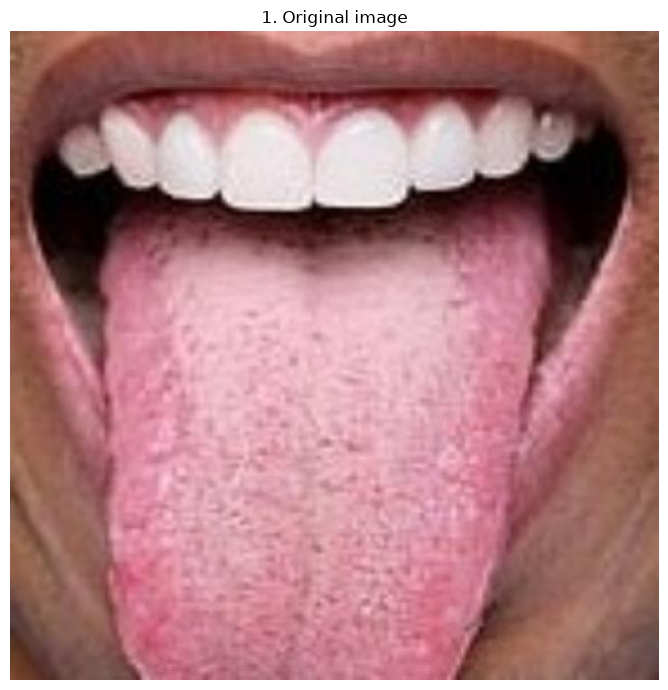

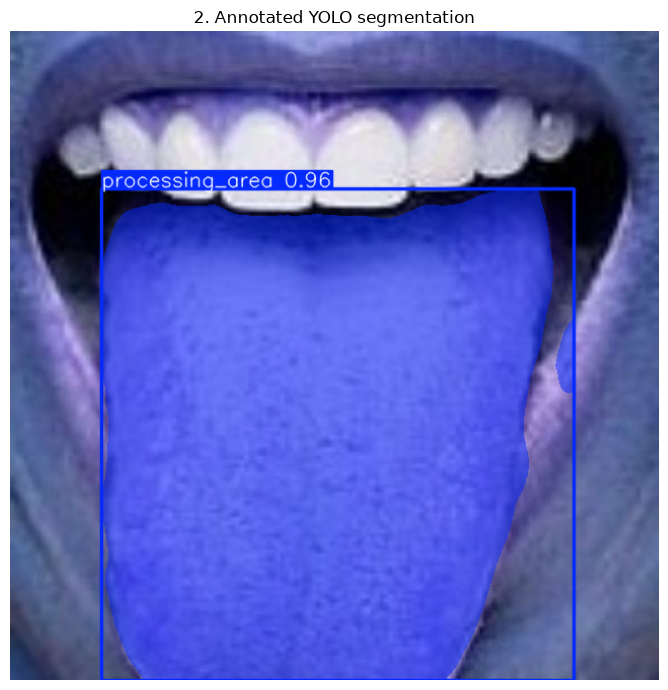

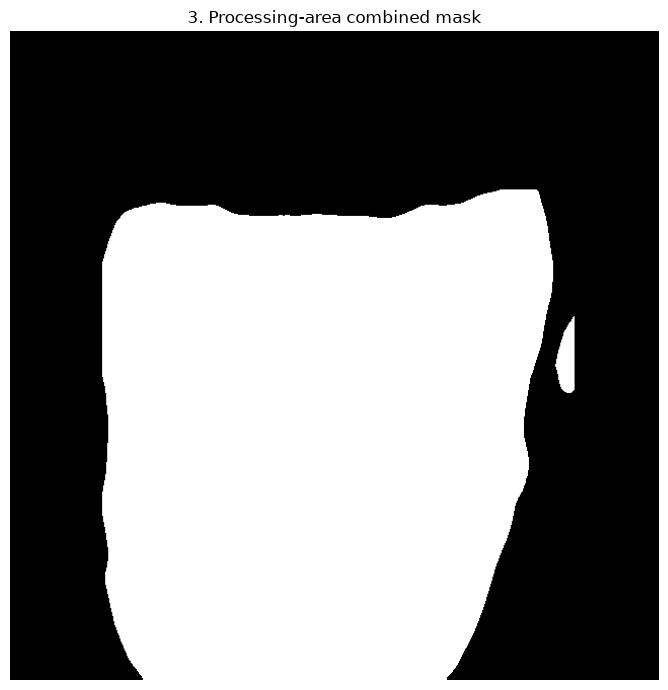

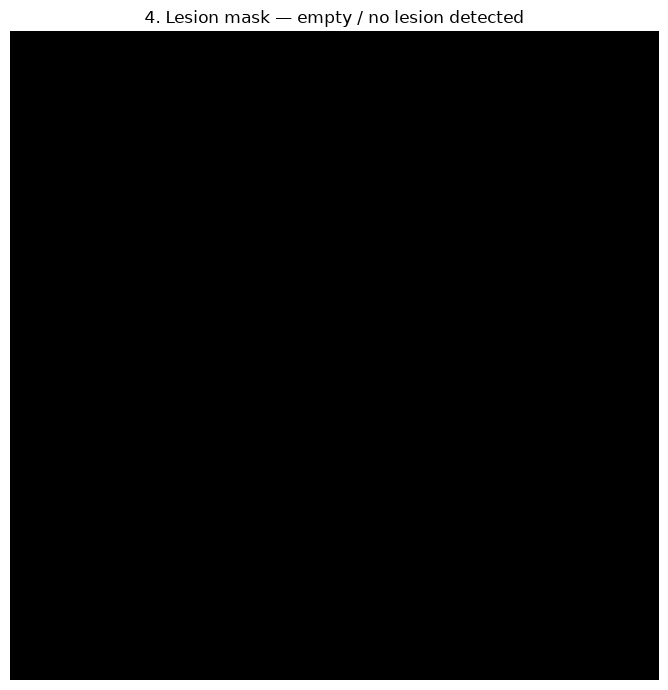

In [ ]:
# ============================================================
# ORALSCAN CUSTOM INFERENCE — NO FILES / NO ZIP / INLINE OUTPUT
# ============================================================

# Install only if Ultralytics is unavailable in current runtime.
try:
    from ultralytics import YOLO
except ImportError:
    %pip install -q ultralytics
    from ultralytics import YOLO

import io
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files
from IPython.display import display


# ============================================================
# CONFIGURATION
# ============================================================

MODEL_PATH = "/content/best_oralscan_yolo26m_seg.pt"

EXPECTED_CLASS_NAMES = {
    0: "processing_area",
    1: "lesion"
}


# ============================================================
# MODEL LOADER
# ============================================================

def load_oralscan_model(model_path=MODEL_PATH):
    """
    Load and verify the trained OralScan YOLO segmentation model.

    Returns
    -------
    ultralytics.YOLO
        Loaded model.
    """

    print("=" * 80)
    print("LOADING ORALSCAN MODEL")
    print("=" * 80)
    print(f"Model path : {model_path}")

    model = YOLO(model_path)

    model_names = {
        int(class_id): str(class_name)
        for class_id, class_name in model.names.items()
    }

    print(f"Classes    : {model_names}")

    if model_names != EXPECTED_CLASS_NAMES:
        raise ValueError(
            "\nModel class mapping is not correct.\n"
            f"Expected: {EXPECTED_CLASS_NAMES}\n"
            f"Found   : {model_names}"
        )

    print("✅ Model loaded and class mapping verified.\n")

    return model


# ============================================================
# IMAGE UPLOADER
# ============================================================

def upload_single_image():
    """
    Open the Colab upload dialog and return one RGB image.

    Returns
    -------
    tuple
        filename, RGB numpy image
    """

    print("Upload one oral image:")

    uploaded = files.upload()

    if not uploaded:
        raise RuntimeError("No image was uploaded.")

    filename = next(iter(uploaded))
    image_bytes = uploaded[filename]

    try:
        pil_image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

    except Exception as error:
        raise ValueError(
            f"Uploaded file is not a readable image: {filename}"
        ) from error

    image_rgb = np.asarray(pil_image)

    print(f"\n✅ Uploaded       : {filename}")
    print(f"Original size    : {image_rgb.shape[1]} × {image_rgb.shape[0]}")
    print(f"Image channels   : {image_rgb.shape[2]}")

    return filename, image_rgb


# ============================================================
# MASK HELPER
# ============================================================

def resize_binary_mask(mask, target_width, target_height):
    """
    Resize a predicted mask to the original image size and
    convert it into a binary uint8 mask: 0 or 255.
    """

    resized = cv2.resize(
        mask.astype(np.float32),
        (target_width, target_height),
        interpolation=cv2.INTER_NEAREST
    )

    return (
        resized > 0.5
    ).astype(np.uint8) * 255


# ============================================================
# DISPLAY HELPER
# ============================================================

def show_image(title, image, grayscale=False):
    """
    Display one image in its own figure.
    """

    plt.figure(figsize=(8, 7))

    if grayscale:
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        plt.imshow(image)

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ============================================================
# MAIN INFERENCE FUNCTION
# ============================================================

def run_oralscan_inference(
    model,
    image_rgb,
    image_name="uploaded_image",
    confidence_threshold=0.25,
    iou_threshold=0.60,
    image_size=640,
    max_polygon_points_to_print=20
):
    """
    Run OralScan instance segmentation and display all results inline.

    No output file or folder is created.

    Parameters
    ----------
    model:
        Loaded Ultralytics YOLO model.

    image_rgb:
        Input image as an RGB NumPy array.

    image_name:
        Name used only in terminal output.

    confidence_threshold:
        Minimum detection confidence.

    iou_threshold:
        NMS IoU threshold.

    image_size:
        YOLO inference resolution.

    max_polygon_points_to_print:
        Maximum number of polygon points displayed per detection.
        All polygon points remain available in the returned dictionary.

    Returns
    -------
    dict
        Structured inference result for frontend/API integration.
    """

    if not isinstance(image_rgb, np.ndarray):
        raise TypeError(
            "image_rgb must be a NumPy array."
        )

    if image_rgb.ndim != 3 or image_rgb.shape[2] != 3:
        raise ValueError(
            "Input must be an RGB image with shape H × W × 3."
        )

    original_height, original_width = image_rgb.shape[:2]

    device = 0 if torch.cuda.is_available() else "cpu"

    print("\n" + "=" * 88)
    print("ORALSCAN SEGMENTATION INFERENCE")
    print("=" * 88)

    print(f"Image                 : {image_name}")
    print(f"Original dimensions   : {original_width} × {original_height}")
    print(f"Inference size        : {image_size}")
    print(f"Confidence threshold  : {confidence_threshold}")
    print(f"IoU threshold         : {iou_threshold}")
    print(f"Device                : {device}")

    if torch.cuda.is_available():
        print(f"GPU                   : {torch.cuda.get_device_name(0)}")

    print("=" * 88)

    # --------------------------------------------------------
    # RUN PREDICTION
    # --------------------------------------------------------

    predictions = model.predict(
        source=image_rgb,
        imgsz=image_size,
        conf=confidence_threshold,
        iou=iou_threshold,
        device=device,
        retina_masks=True,
        verbose=False
    )

    if not predictions:
        raise RuntimeError(
            "YOLO returned no prediction result."
        )

    result = predictions[0]

    # Ultralytics plot() returns BGR.
    annotated_bgr = result.plot(
        boxes=True,
        labels=True,
        conf=True,
        masks=True
    )

    annotated_rgb = cv2.cvtColor(
        annotated_bgr,
        cv2.COLOR_BGR2RGB
    )

    # Fixed-size combined masks.
    processing_area_mask = np.zeros(
        (original_height, original_width),
        dtype=np.uint8
    )

    lesion_mask = np.zeros(
        (original_height, original_width),
        dtype=np.uint8
    )

    detections = []
    processing_detections = []
    lesion_detections = []

    # --------------------------------------------------------
    # HANDLE NO-DETECTION RESULT
    # --------------------------------------------------------

    if (
        result.boxes is None
        or len(result.boxes) == 0
    ):
        print("\n⚠️ No objects were detected above the threshold.")

        response = {
            "status": "success",
            "image_name": image_name,
            "image_width": original_width,
            "image_height": original_height,
            "processing_area_detected": False,
            "processing_area_count": 0,
            "lesion_detected": False,
            "lesion_count": 0,
            "total_detections": 0,
            "detections": [],
            "annotated_image_rgb": annotated_rgb,
            "processing_area_mask": processing_area_mask,
            "lesion_mask": lesion_mask
        }

        show_image(
            "Original image",
            image_rgb
        )

        show_image(
            "Annotated prediction — no detections",
            annotated_rgb
        )

        show_image(
            "Processing-area mask — empty",
            processing_area_mask,
            grayscale=True
        )

        show_image(
            "Lesion mask — empty",
            lesion_mask,
            grayscale=True
        )

        return response

    # --------------------------------------------------------
    # EXTRACT BOX AND CLASS INFORMATION
    # --------------------------------------------------------

    boxes_xyxy = (
        result.boxes.xyxy
        .detach()
        .cpu()
        .numpy()
    )

    confidences = (
        result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    class_ids = (
        result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    # Full-resolution masks.
    mask_data = None

    if (
        result.masks is not None
        and result.masks.data is not None
    ):
        mask_data = (
            result.masks.data
            .detach()
            .cpu()
            .numpy()
        )

    # Original-image-coordinate polygon boundaries.
    polygons_xy = []

    if (
        result.masks is not None
        and result.masks.xy is not None
    ):
        polygons_xy = result.masks.xy

    # --------------------------------------------------------
    # PROCESS EACH DETECTION
    # --------------------------------------------------------

    for detection_index in range(len(class_ids)):
        class_id = int(class_ids[detection_index])
        class_name = str(model.names[class_id])
        confidence = float(confidences[detection_index])

        x1, y1, x2, y2 = boxes_xyxy[detection_index]

        bbox = {
            "x1": round(float(x1), 2),
            "y1": round(float(y1), 2),
            "x2": round(float(x2), 2),
            "y2": round(float(y2), 2),
            "width": round(float(x2 - x1), 2),
            "height": round(float(y2 - y1), 2)
        }

        # Obtain individual binary mask.
        if (
            mask_data is not None
            and detection_index < len(mask_data)
        ):
            binary_mask = resize_binary_mask(
                mask_data[detection_index],
                target_width=original_width,
                target_height=original_height
            )
        else:
            binary_mask = np.zeros(
                (original_height, original_width),
                dtype=np.uint8
            )

        # Combine all instances belonging to the same class.
        if class_id == 0:
            processing_area_mask = np.maximum(
                processing_area_mask,
                binary_mask
            )
        elif class_id == 1:
            lesion_mask = np.maximum(
                lesion_mask,
                binary_mask
            )

        # Extract full polygon.
        polygon_points = []

        if detection_index < len(polygons_xy):
            polygon_array = np.asarray(
                polygons_xy[detection_index],
                dtype=np.float32
            )

            polygon_points = [
                {
                    "x": round(float(point[0]), 2),
                    "y": round(float(point[1]), 2)
                }
                for point in polygon_array
            ]

        mask_pixels = int(
            np.count_nonzero(binary_mask)
        )

        mask_percentage = (
            mask_pixels
            / float(original_width * original_height)
            * 100.0
        )

        detection_record = {
            "detection_id": detection_index + 1,
            "class_id": class_id,
            "class_name": class_name,
            "confidence": round(confidence, 6),
            "bbox_xyxy": bbox,
            "polygon_point_count": len(polygon_points),
            "polygon_points": polygon_points,
            "mask_pixel_area": mask_pixels,
            "mask_image_percentage": round(
                mask_percentage,
                4
            ),
            "binary_mask": binary_mask
        }

        detections.append(detection_record)

        if class_id == 0:
            processing_detections.append(detection_record)
        elif class_id == 1:
            lesion_detections.append(detection_record)

    # --------------------------------------------------------
    # TERMINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 88)
    print("PREDICTION SUMMARY")
    print("=" * 88)

    print(f"Total detections        : {len(detections)}")
    print(f"Processing-area count   : {len(processing_detections)}")
    print(f"Lesion count            : {len(lesion_detections)}")

    print(
        f"Processing area detected: "
        f"{len(processing_detections) > 0}"
    )

    print(
        f"Lesion detected         : "
        f"{len(lesion_detections) > 0}"
    )

    if processing_detections:
        best_processing_confidence = max(
            detection["confidence"]
            for detection in processing_detections
        )

        print(
            f"Best processing conf.   : "
            f"{best_processing_confidence:.4f}"
        )
    else:
        print("Best processing conf.   : Not detected")

    if lesion_detections:
        best_lesion_confidence = max(
            detection["confidence"]
            for detection in lesion_detections
        )

        print(
            f"Best lesion confidence  : "
            f"{best_lesion_confidence:.4f}"
        )
    else:
        print("Best lesion confidence  : Not detected")

    # --------------------------------------------------------
    # DETAILED DETECTION OUTPUT
    # --------------------------------------------------------

    for detection in detections:
        print("\n" + "-" * 88)

        print(
            f"Detection #{detection['detection_id']}"
        )

        print(
            f"Class            : "
            f"{detection['class_name']} "
            f"(ID {detection['class_id']})"
        )

        print(
            f"Confidence       : "
            f"{detection['confidence']:.4f}"
        )

        bbox = detection["bbox_xyxy"]

        print(
            "Bounding box     : "
            f"[x1={bbox['x1']}, y1={bbox['y1']}, "
            f"x2={bbox['x2']}, y2={bbox['y2']}]"
        )

        print(
            f"Box dimensions   : "
            f"{bbox['width']} × {bbox['height']} pixels"
        )

        print(
            f"Mask pixel area  : "
            f"{detection['mask_pixel_area']} pixels"
        )

        print(
            f"Image coverage   : "
            f"{detection['mask_image_percentage']:.4f}%"
        )

        print(
            f"Polygon points   : "
            f"{detection['polygon_point_count']}"
        )

        points = detection["polygon_points"]

        if not points:
            print("Polygon preview  : Not available")
        else:
            visible_points = points[
                :max_polygon_points_to_print
            ]

            print("Polygon preview  :")

            for point_index, point in enumerate(
                visible_points,
                start=1
            ):
                print(
                    f"  Point {point_index:03d}: "
                    f"({point['x']}, {point['y']})"
                )

            hidden_count = (
                len(points) - len(visible_points)
            )

            if hidden_count > 0:
                print(
                    f"  ... {hidden_count} additional points "
                    "available in returned result dictionary."
                )

    # --------------------------------------------------------
    # FINAL STATUS
    # --------------------------------------------------------

    print("\n" + "=" * 88)
    print("FINAL STATUS")
    print("=" * 88)

    if processing_detections and lesion_detections:
        print(
            "Processing area detected and lesion detected."
        )

    elif processing_detections and not lesion_detections:
        print(
            "Processing area detected; no lesion detected."
        )

    elif not processing_detections and lesion_detections:
        print(
            "Lesion detected, but processing area was not detected. "
            "This prediction should be reviewed."
        )

    else:
        print(
            "Neither processing area nor lesion was detected."
        )

    # --------------------------------------------------------
    # INLINE VISUAL OUTPUT
    # --------------------------------------------------------

    show_image(
        "1. Original image",
        image_rgb
    )

    show_image(
        "2. Annotated YOLO segmentation",
        annotated_rgb
    )

    show_image(
        (
            "3. Processing-area combined mask"
            if processing_detections
            else "3. Processing-area mask — empty"
        ),
        processing_area_mask,
        grayscale=True
    )

    show_image(
        (
            "4. Lesion combined mask"
            if lesion_detections
            else "4. Lesion mask — empty / no lesion detected"
        ),
        lesion_mask,
        grayscale=True
    )

    # --------------------------------------------------------
    # STRUCTURED RESPONSE
    # --------------------------------------------------------

    response = {
        "status": "success",
        "image_name": image_name,
        "image_width": original_width,
        "image_height": original_height,

        "processing_area_detected":
            len(processing_detections) > 0,

        "processing_area_count":
            len(processing_detections),

        "lesion_detected":
            len(lesion_detections) > 0,

        "lesion_count":
            len(lesion_detections),

        "total_detections":
            len(detections),

        "detections":
            detections,

        # In-memory outputs; no files are created.
        "annotated_image_rgb":
            annotated_rgb,

        "processing_area_mask":
            processing_area_mask,

        "lesion_mask":
            lesion_mask
    }

    return response


# ============================================================
# EASY WRAPPER: LOAD MODEL → UPLOAD IMAGE → PREDICT
# ============================================================

def oralscan_predict(
    model_path=MODEL_PATH,
    confidence_threshold=0.25,
    iou_threshold=0.60,
    image_size=640
):
    """
    Complete one-call workflow:

    1. Load model
    2. Upload one image
    3. Run segmentation
    4. Print terminal results
    5. Display images and masks
    6. Return structured dictionary
    """

    model = load_oralscan_model(
        model_path=model_path
    )

    filename, image_rgb = upload_single_image()

    result = run_oralscan_inference(
        model=model,
        image_rgb=image_rgb,
        image_name=filename,
        confidence_threshold=confidence_threshold,
        iou_threshold=iou_threshold,
        image_size=image_size
    )

    return result


# ============================================================
# RUN
# ============================================================

oralscan_result = oralscan_predict(
    model_path="/content/best_oralscan_yolo26m_seg.pt",
    confidence_threshold=0.25,
    iou_threshold=0.60,
    image_size=640
)

In [ ]:
print(oralscan_result["lesion_detected"])
print(oralscan_result["lesion_count"])
print(oralscan_result["processing_area_detected"])
print(oralscan_result["processing_area_count"])

True
3
True
2


In [ ]:
# ============================================================
# CELL 1: INSTALLATION + CONFIGURATION
# ============================================================

%pip install -q --no-cache-dir ultralytics opencv-python-headless

import os
import io
import gc
import csv
import json
import yaml
import shutil
import zipfile
import warnings

from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import torch

from PIL import Image
from ultralytics import YOLO
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

SOURCE_DATASET_ZIP = Path(
    "/content/DataSet-20260805T051501Z-1-001.zip"
)

YOLO_MODEL_PATH = Path(
    "/content/best_oralscan_yolo26m_seg.pt"
)

WORKSPACE = Path(
    "/content/oralscan_classifier_builder"
)

EXTRACT_DIR = WORKSPACE / "extracted"
OUTPUT_DATASET_DIR = WORKSPACE / "classifier_dataset"

OUTPUT_ZIP_PATH = Path(
    "/content/OralScan_Classifier_Dataset.zip"
)

# ------------------------------------------------------------
# YOLO CLASS ORDER
# ------------------------------------------------------------

EXPECTED_YOLO_CLASSES = {
    0: "processing_area",
    1: "lesion"
}

# ------------------------------------------------------------
# CLASSIFIER CLASSES
# ------------------------------------------------------------

CLASSIFIER_CLASSES = (
    "cancer",
    "leukoplakia",
    "leukoplakia_like",
    "normal"
)

# ------------------------------------------------------------
# INFERENCE SETTINGS
# ------------------------------------------------------------

IMAGE_SIZE = 640
CONFIDENCE_THRESHOLD = 0.25
IOU_THRESHOLD = 0.60

# Crop ke charon taraf percentage padding.
CROP_PADDING_RATIO = 0.15

# Bahut chhoti lesion predictions skip hongi.
MIN_LESION_PIXELS = 100

# Classifier crop fixed output size.
CLASSIFIER_IMAGE_SIZE = 224

DEVICE = 0 if torch.cuda.is_available() else "cpu"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

# ------------------------------------------------------------
# CHECKS
# ------------------------------------------------------------

if not SOURCE_DATASET_ZIP.exists():
    raise FileNotFoundError(
        f"Dataset ZIP not found:\n{SOURCE_DATASET_ZIP}"
    )

if not YOLO_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"YOLO model not found:\n{YOLO_MODEL_PATH}"
    )

model = YOLO(str(YOLO_MODEL_PATH))

model_names = {
    int(class_id): str(class_name)
    for class_id, class_name in model.names.items()
}

if model_names != EXPECTED_YOLO_CLASSES:
    raise RuntimeError(
        "YOLO class mapping mismatch.\n"
        f"Expected: {EXPECTED_YOLO_CLASSES}\n"
        f"Found:    {model_names}"
    )

print("=" * 80)
print("CLASSIFIER DATASET GENERATOR")
print("=" * 80)
print(f"Source ZIP       : {SOURCE_DATASET_ZIP}")
print(f"YOLO model       : {YOLO_MODEL_PATH}")
print(f"YOLO classes     : {model_names}")
print(f"Classifier size  : {CLASSIFIER_IMAGE_SIZE} × {CLASSIFIER_IMAGE_SIZE}")
print(f"Device           : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU              : {torch.cuda.get_device_name(0)}")

print("✅ CELL 1 completed.")


CLASSIFIER DATASET GENERATOR
Source ZIP       : /content/DataSet-20260805T051501Z-1-001.zip
YOLO model       : /content/best_oralscan_yolo26m_seg.pt
YOLO classes     : {0: 'processing_area', 1: 'lesion'}
Classifier size  : 224 × 224
Device           : 0
GPU              : NVIDIA A100-SXM4-40GB
✅ CELL 1 completed.


In [ ]:
# ============================================================
# CELL 2: EXTRACT + DISCOVER SOURCE DATASETS
# ============================================================


def normalize_name(text):
    return (
        str(text)
        .strip()
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )


def identify_classifier_class(dataset_folder_name, yaml_names):
    """
    Source dataset ko final classifier class mein map karta hai.
    """

    combined_text = normalize_name(
        dataset_folder_name + " " + " ".join(yaml_names)
    )

    if "leukoplakia_like" in combined_text:
        return "leukoplakia_like"

    if "cancer" in combined_text:
        return "cancer"

    if "leukoplakia" in combined_text:
        return "leukoplakia"

    if (
        "processing_area" in combined_text
        or "normal" in combined_text
        or "mucosa" in combined_text
    ):
        return "normal"

    raise ValueError(
        f"Could not identify dataset category: {dataset_folder_name}"
    )


def yaml_names_as_list(names):
    if isinstance(names, list):
        return [str(value) for value in names]

    if isinstance(names, dict):
        return [
            str(names[key])
            for key in sorted(names, key=lambda value: int(value))
        ]

    return []


def resolve_split_images(dataset_folder, split):
    aliases = {
        "train": ("train",),
        "valid": ("valid", "val"),
        "test": ("test",)
    }

    for alias in aliases[split]:
        images_dir = dataset_folder / alias / "images"

        if images_dir.is_dir():
            return images_dir

    return None


# ------------------------------------------------------------
# EXTRACT CLEANLY
# ------------------------------------------------------------

if WORKSPACE.exists():
    shutil.rmtree(WORKSPACE)

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DATASET_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(SOURCE_DATASET_ZIP, "r") as archive:
    archive.extractall(EXTRACT_DIR)

# ------------------------------------------------------------
# CREATE OUTPUT FOLDERS
# ------------------------------------------------------------

for split in ("train", "valid", "test"):
    for class_name in CLASSIFIER_CLASSES:
        class_dir = (
            OUTPUT_DATASET_DIR /
            split /
            class_name
        )

        class_dir.mkdir(
            parents=True,
            exist_ok=True
        )

# ------------------------------------------------------------
# DISCOVER DATA.YAML FILES
# ------------------------------------------------------------

source_datasets = []

for yaml_path in sorted(EXTRACT_DIR.rglob("data.yaml")):
    dataset_folder = yaml_path.parent

    if not any(
        (dataset_folder / split / "images").is_dir()
        for split in ("train", "valid", "val", "test")
    ):
        continue

    with open(yaml_path, "r", encoding="utf-8") as file:
        config = yaml.safe_load(file)

    yaml_names = yaml_names_as_list(
        config.get("names", [])
    )

    classifier_class = identify_classifier_class(
        dataset_folder.name,
        yaml_names
    )

    source_datasets.append({
        "dataset_folder": dataset_folder,
        "yaml_path": yaml_path,
        "classifier_class": classifier_class,
        "source_names": yaml_names
    })

print("=" * 90)
print("DISCOVERED SOURCE DATASETS")
print("=" * 90)

for item in source_datasets:
    print(
        f"{item['dataset_folder'].name:<45} "
        f"→ {item['classifier_class']}"
    )

if len(source_datasets) != 4:
    print(
        f"\n⚠️ Expected 4 datasets, discovered {len(source_datasets)}."
    )

print("\n✅ CELL 2 completed.")

DISCOVERED SOURCE DATASETS
cancer_detection.v1i.yolov11                  → cancer
leukoplakia_detection.v1i.yolov11             → leukoplakia
leukoplakia_like_detection.v1i.yolov11        → leukoplakia_like
processing_area.v2i.yolov11                   → normal

✅ CELL 2 completed.


In [ ]:
# ============================================================
# CELL 3: RUN YOLO AND BUILD CLASSIFIER DATASET
# ============================================================


def resize_binary_mask(mask, width, height):
    resized = cv2.resize(
        mask.astype(np.float32),
        (width, height),
        interpolation=cv2.INTER_NEAREST
    )

    return (resized > 0.5).astype(np.uint8) * 255


def mask_bounding_box(mask):
    """
    Binary mask se x1, y1, x2, y2 bbox.
    """

    ys, xs = np.where(mask > 0)

    if len(xs) == 0 or len(ys) == 0:
        return None

    return (
        int(xs.min()),
        int(ys.min()),
        int(xs.max()) + 1,
        int(ys.max()) + 1
    )


def padded_bbox(bbox, image_width, image_height, padding_ratio=0.15):
    x1, y1, x2, y2 = bbox

    box_width = x2 - x1
    box_height = y2 - y1

    pad_x = int(box_width * padding_ratio)
    pad_y = int(box_height * padding_ratio)

    return (
        max(0, x1 - pad_x),
        max(0, y1 - pad_y),
        min(image_width, x2 + pad_x),
        min(image_height, y2 + pad_y)
    )


def square_bbox(bbox, image_width, image_height):
    """
    Crop ko approximate square banata hai.
    """

    x1, y1, x2, y2 = bbox

    width = x2 - x1
    height = y2 - y1
    side = max(width, height)

    center_x = (x1 + x2) // 2
    center_y = (y1 + y2) // 2

    new_x1 = center_x - side // 2
    new_y1 = center_y - side // 2
    new_x2 = new_x1 + side
    new_y2 = new_y1 + side

    if new_x1 < 0:
        new_x2 -= new_x1
        new_x1 = 0

    if new_y1 < 0:
        new_y2 -= new_y1
        new_y1 = 0

    if new_x2 > image_width:
        shift = new_x2 - image_width
        new_x1 = max(0, new_x1 - shift)
        new_x2 = image_width

    if new_y2 > image_height:
        shift = new_y2 - image_height
        new_y1 = max(0, new_y1 - shift)
        new_y2 = image_height

    return (
        int(new_x1),
        int(new_y1),
        int(new_x2),
        int(new_y2)
    )


def predict_combined_masks(image_rgb):
    """
    Returns:
      combined processing-area mask
      combined lesion mask
      detection details
    """

    height, width = image_rgb.shape[:2]

    result = model.predict(
        source=image_rgb,
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        iou=IOU_THRESHOLD,
        device=DEVICE,
        retina_masks=True,
        verbose=False
    )[0]

    processing_mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    lesion_mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    processing_confidences = []
    lesion_confidences = []

    if (
        result.boxes is None
        or len(result.boxes) == 0
        or result.masks is None
    ):
        return {
            "processing_mask": processing_mask,
            "lesion_mask": lesion_mask,
            "processing_confidences": [],
            "lesion_confidences": []
        }

    class_ids = (
        result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    masks = (
        result.masks.data
        .detach()
        .cpu()
        .numpy()
    )

    for index, class_id in enumerate(class_ids):
        individual_mask = resize_binary_mask(
            masks[index],
            width,
            height
        )

        confidence = float(confidences[index])

        if class_id == 0:
            processing_mask = np.maximum(
                processing_mask,
                individual_mask
            )

            processing_confidences.append(confidence)

        elif class_id == 1:
            lesion_mask = np.maximum(
                lesion_mask,
                individual_mask
            )

            lesion_confidences.append(confidence)

    return {
        "processing_mask": processing_mask,
        "lesion_mask": lesion_mask,
        "processing_confidences": processing_confidences,
        "lesion_confidences": lesion_confidences
    }


def save_classifier_pair(
    image_rgb,
    binary_mask,
    bbox,
    destination_directory,
    sample_stem
):
    """
    RGB aur mask same crop/resize ke saath save karta hai.
    """

    height, width = image_rgb.shape[:2]

    bbox = padded_bbox(
        bbox,
        width,
        height,
        CROP_PADDING_RATIO
    )

    bbox = square_bbox(
        bbox,
        width,
        height
    )

    x1, y1, x2, y2 = bbox

    rgb_crop = image_rgb[y1:y2, x1:x2]
    mask_crop = binary_mask[y1:y2, x1:x2]

    if rgb_crop.size == 0:
        raise ValueError("Generated RGB crop is empty.")

    rgb_crop = cv2.resize(
        rgb_crop,
        (CLASSIFIER_IMAGE_SIZE, CLASSIFIER_IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    mask_crop = cv2.resize(
        mask_crop,
        (CLASSIFIER_IMAGE_SIZE, CLASSIFIER_IMAGE_SIZE),
        interpolation=cv2.INTER_NEAREST
    )

    mask_crop = (
        mask_crop > 127
    ).astype(np.uint8) * 255

    rgb_path = (
        destination_directory /
        f"{sample_stem}_rgb.jpg"
    )

    mask_path = (
        destination_directory /
        f"{sample_stem}_mask.png"
    )

    Image.fromarray(rgb_crop).save(
        rgb_path,
        quality=95
    )

    Image.fromarray(mask_crop).save(
        mask_path
    )

    return rgb_path, mask_path, bbox


# ------------------------------------------------------------
# BUILD DATASET
# ------------------------------------------------------------

manifest_records = []
skipped_records = []
counter = Counter()

total_source_images = 0

for dataset_item in source_datasets:
    dataset_folder = dataset_item["dataset_folder"]
    classifier_class = dataset_item["classifier_class"]

    print("\n" + "=" * 95)
    print(
        f"PROCESSING: {dataset_folder.name} "
        f"→ {classifier_class}"
    )
    print("=" * 95)

    for split in ("train", "valid", "test"):
        images_dir = resolve_split_images(
            dataset_folder,
            split
        )

        if images_dir is None:
            continue

        image_paths = sorted([
            path
            for path in images_dir.iterdir()
            if path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        ])

        print(
            f"{split:<6}: {len(image_paths)} images"
        )

        for image_index, image_path in enumerate(
            image_paths,
            start=1
        ):
            total_source_images += 1

            try:
                image_rgb = np.asarray(
                    Image.open(image_path).convert("RGB")
                )

                prediction = predict_combined_masks(
                    image_rgb
                )

                processing_mask = prediction["processing_mask"]
                lesion_mask = prediction["lesion_mask"]

                processing_pixels = int(
                    np.count_nonzero(processing_mask)
                )

                lesion_pixels = int(
                    np.count_nonzero(lesion_mask)
                )

                destination_dir = (
                    OUTPUT_DATASET_DIR /
                    split /
                    classifier_class
                )

                safe_dataset_name = "".join(
                    character if character.isalnum() else "_"
                    for character in dataset_folder.name
                ).strip("_")

                sample_stem = (
                    f"{safe_dataset_name}"
                    f"__{image_path.stem}"
                )

                # ------------------------------------------------
                # DISEASE CLASSES
                # ------------------------------------------------

                if classifier_class != "normal":
                    if lesion_pixels < MIN_LESION_PIXELS:
                        raise ValueError(
                            "YOLO did not detect a sufficiently large lesion"
                        )

                    crop_bbox = mask_bounding_box(
                        lesion_mask
                    )

                    if crop_bbox is None:
                        raise ValueError(
                            "Lesion bounding box could not be created"
                        )

                    rgb_path, mask_path, final_bbox = (
                        save_classifier_pair(
                            image_rgb=image_rgb,
                            binary_mask=lesion_mask,
                            bbox=crop_bbox,
                            destination_directory=destination_dir,
                            sample_stem=sample_stem
                        )
                    )

                # ------------------------------------------------
                # NORMAL CLASS
                # ------------------------------------------------

                else:
                    # Normal sample mein predicted lesion nahi hona chahiye.
                    if lesion_pixels >= MIN_LESION_PIXELS:
                        raise ValueError(
                            "YOLO predicted a lesion in a normal-source image"
                        )

                    # Normal ka RGB crop gum/processing area se.
                    crop_bbox = mask_bounding_box(
                        processing_mask
                    )

                    if crop_bbox is None:
                        raise ValueError(
                            "YOLO did not detect processing_area"
                        )

                    # Fixed black lesion mask.
                    empty_lesion_mask = np.zeros_like(
                        processing_mask,
                        dtype=np.uint8
                    )

                    rgb_path, mask_path, final_bbox = (
                        save_classifier_pair(
                            image_rgb=image_rgb,
                            binary_mask=empty_lesion_mask,
                            bbox=crop_bbox,
                            destination_directory=destination_dir,
                            sample_stem=sample_stem
                        )
                    )

                manifest_records.append({
                    "split": split,
                    "class_name": classifier_class,
                    "source_dataset": dataset_folder.name,
                    "source_image": str(image_path),
                    "rgb_file": str(
                        rgb_path.relative_to(OUTPUT_DATASET_DIR)
                    ),
                    "mask_file": str(
                        mask_path.relative_to(OUTPUT_DATASET_DIR)
                    ),
                    "crop_x1": final_bbox[0],
                    "crop_y1": final_bbox[1],
                    "crop_x2": final_bbox[2],
                    "crop_y2": final_bbox[3],
                    "processing_pixels": processing_pixels,
                    "lesion_pixels": lesion_pixels,
                    "best_processing_confidence": (
                        max(prediction["processing_confidences"])
                        if prediction["processing_confidences"]
                        else None
                    ),
                    "best_lesion_confidence": (
                        max(prediction["lesion_confidences"])
                        if prediction["lesion_confidences"]
                        else None
                    )
                })

                counter[(split, classifier_class)] += 1

            except Exception as error:
                skipped_records.append({
                    "split": split,
                    "class_name": classifier_class,
                    "source_dataset": dataset_folder.name,
                    "source_image": str(image_path),
                    "reason": str(error)
                })

            if image_index % 25 == 0:
                print(
                    f"  Processed {image_index}/{len(image_paths)}"
                )

# ------------------------------------------------------------
# SAVE REPORTS
# ------------------------------------------------------------

manifest_df = pd.DataFrame(
    manifest_records
)

skipped_df = pd.DataFrame(
    skipped_records
)

manifest_path = (
    OUTPUT_DATASET_DIR /
    "manifest.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False
)

if not skipped_df.empty:
    skipped_path = (
        OUTPUT_DATASET_DIR /
        "skipped_samples.csv"
    )

    skipped_df.to_csv(
        skipped_path,
        index=False
    )

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

summary_df = (
    manifest_df
    .groupby(
        ["split", "class_name"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "samples"})
)

print("\n" + "=" * 100)
print("CLASSIFIER DATASET SUMMARY")
print("=" * 100)

display(summary_df)

print(f"\nTotal source images : {total_source_images}")
print(f"Created samples     : {len(manifest_df)}")
print(f"Skipped samples     : {len(skipped_df)}")

if not skipped_df.empty:
    print("\nSkipped reason summary:")

    display(
        skipped_df["reason"]
        .value_counts()
        .rename_axis("reason")
        .reset_index(name="count")
    )

print("\n✅ CELL 3 completed.")



PROCESSING: cancer_detection.v1i.yolov11 → cancer
train : 140 images
  Processed 25/140
  Processed 50/140
  Processed 75/140
  Processed 100/140
  Processed 125/140
valid : 40 images
  Processed 25/40
test  : 20 images

PROCESSING: leukoplakia_detection.v1i.yolov11 → leukoplakia
train : 140 images
  Processed 25/140
  Processed 50/140
  Processed 75/140
  Processed 100/140
  Processed 125/140
valid : 38 images
  Processed 25/38
test  : 22 images

PROCESSING: leukoplakia_like_detection.v1i.yolov11 → leukoplakia_like
train : 142 images
  Processed 25/142
  Processed 50/142
  Processed 75/142
  Processed 100/142
  Processed 125/142
valid : 40 images
  Processed 25/40
test  : 20 images

PROCESSING: processing_area.v2i.yolov11 → normal
train : 155 images
  Processed 25/155
  Processed 50/155
  Processed 75/155
  Processed 100/155
  Processed 125/155
  Processed 150/155
valid : 40 images
  Processed 25/40
test  : 20 images

CLASSIFIER DATASET SUMMARY


,split,class_name,samples
0,test,cancer,16
1,test,leukoplakia,17
2,test,leukoplakia_like,11
3,test,normal,14
4,train,cancer,122
5,train,leukoplakia,98
6,train,leukoplakia_like,111
7,train,normal,130
8,valid,cancer,26
9,valid,leukoplakia,18



Total source images : 817
Created samples     : 619
Skipped samples     : 198

Skipped reason summary:


,reason,count
0,YOLO did not detect a sufficiently large lesion,161
1,YOLO predicted a lesion in a normal-source image,35
2,YOLO did not detect processing_area,2



✅ CELL 3 completed.


In [ ]:
# ============================================================
# CELL 4: VERIFY + ZIP + DOWNLOAD
# ============================================================

from google.colab import files


def verify_classifier_dataset(dataset_root):
    problems = []
    records = []

    for split in ("train", "valid", "test"):
        for class_name in CLASSIFIER_CLASSES:
            class_dir = (
                dataset_root /
                split /
                class_name
            )

            rgb_files = sorted(
                class_dir.glob("*_rgb.jpg")
            )

            mask_files = sorted(
                class_dir.glob("*_mask.png")
            )

            rgb_stems = {
                path.name.replace("_rgb.jpg", "")
                for path in rgb_files
            }

            mask_stems = {
                path.name.replace("_mask.png", "")
                for path in mask_files
            }

            missing_masks = rgb_stems - mask_stems
            missing_rgb = mask_stems - rgb_stems

            for stem in missing_masks:
                problems.append({
                    "split": split,
                    "class": class_name,
                    "sample": stem,
                    "problem": "RGB exists but mask missing"
                })

            for stem in missing_rgb:
                problems.append({
                    "split": split,
                    "class": class_name,
                    "sample": stem,
                    "problem": "Mask exists but RGB missing"
                })

            paired_stems = sorted(
                rgb_stems & mask_stems
            )

            for stem in paired_stems:
                rgb_path = class_dir / f"{stem}_rgb.jpg"
                mask_path = class_dir / f"{stem}_mask.png"

                rgb = np.asarray(
                    Image.open(rgb_path).convert("RGB")
                )

                mask = np.asarray(
                    Image.open(mask_path).convert("L")
                )

                if rgb.shape[:2] != (
                    CLASSIFIER_IMAGE_SIZE,
                    CLASSIFIER_IMAGE_SIZE
                ):
                    problems.append({
                        "split": split,
                        "class": class_name,
                        "sample": stem,
                        "problem": f"Wrong RGB shape: {rgb.shape}"
                    })

                if mask.shape != (
                    CLASSIFIER_IMAGE_SIZE,
                    CLASSIFIER_IMAGE_SIZE
                ):
                    problems.append({
                        "split": split,
                        "class": class_name,
                        "sample": stem,
                        "problem": f"Wrong mask shape: {mask.shape}"
                    })

                unique_mask_values = set(
                    np.unique(mask).tolist()
                )

                if not unique_mask_values.issubset({0, 255}):
                    problems.append({
                        "split": split,
                        "class": class_name,
                        "sample": stem,
                        "problem": (
                            f"Mask is not binary: "
                            f"{sorted(unique_mask_values)[:10]}"
                        )
                    })

                if (
                    class_name == "normal"
                    and np.count_nonzero(mask) != 0
                ):
                    problems.append({
                        "split": split,
                        "class": class_name,
                        "sample": stem,
                        "problem": "Normal mask is not empty"
                    })

            records.append({
                "split": split,
                "class_name": class_name,
                "paired_samples": len(paired_stems)
            })

    return (
        pd.DataFrame(records),
        pd.DataFrame(problems)
    )


verification_df, problems_df = verify_classifier_dataset(
    OUTPUT_DATASET_DIR
)

print("=" * 90)
print("FINAL DATASET VERIFICATION")
print("=" * 90)

display(verification_df)

if not problems_df.empty:
    print("\n⚠️ Verification problems:")
    display(problems_df.head(100))

    problems_df.to_csv(
        OUTPUT_DATASET_DIR /
        "verification_problems.csv",
        index=False
    )

    raise RuntimeError(
        f"Dataset verification found {len(problems_df)} problems."
    )

# ------------------------------------------------------------
# README
# ------------------------------------------------------------

readme_text = f"""
OralScan Classifier Dataset
===========================

Classes:
1. cancer
2. leukoplakia
3. leukoplakia_like
4. normal

Split policy:
Original YOLO train/valid/test splits are preserved.

Each sample contains:
- *_rgb.jpg  : RGB classifier crop
- *_mask.png : paired binary lesion mask

Disease classes:
- RGB crop is generated from the YOLO lesion region.
- Mask contains the predicted lesion.

Normal class:
- RGB crop is generated from processing_area.
- Mask is completely black because no lesion is expected.

Image size:
{CLASSIFIER_IMAGE_SIZE} x {CLASSIFIER_IMAGE_SIZE}

YOLO model:
{YOLO_MODEL_PATH}

YOLO classes:
0 = processing_area
1 = lesion

Important:
Do not randomly re-split individual generated files.
Use the existing train/valid/test directories to avoid leakage.
"""

with open(
    OUTPUT_DATASET_DIR / "README.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(readme_text.strip() + "\n")

# ------------------------------------------------------------
# ZIP
# ------------------------------------------------------------

if OUTPUT_ZIP_PATH.exists():
    OUTPUT_ZIP_PATH.unlink()

archive_base = str(
    OUTPUT_ZIP_PATH.with_suffix("")
)

created_zip = shutil.make_archive(
    base_name=archive_base,
    format="zip",
    root_dir=OUTPUT_DATASET_DIR.parent,
    base_dir=OUTPUT_DATASET_DIR.name
)

zip_size_mb = (
    Path(created_zip).stat().st_size /
    (1024 ** 2)
)

print("\n" + "=" * 90)
print("CLASSIFIER DATASET READY")
print("=" * 90)

print(f"Dataset folder : {OUTPUT_DATASET_DIR}")
print(f"ZIP file       : {created_zip}")
print(f"ZIP size       : {zip_size_mb:.2f} MB")
print(f"Manifest       : {OUTPUT_DATASET_DIR / 'manifest.csv'}")
print("✅ All RGB files have matching binary masks.")
print("✅ Normal masks are empty.")
print("✅ Original split structure is preserved.")

files.download(created_zip)

FINAL DATASET VERIFICATION


,split,class_name,paired_samples
0,train,cancer,122
1,train,leukoplakia,98
2,train,leukoplakia_like,111
3,train,normal,130
4,valid,cancer,26
5,valid,leukoplakia,18
6,valid,leukoplakia_like,22
7,valid,normal,34
8,test,cancer,16
9,test,leukoplakia,17



CLASSIFIER DATASET READY
Dataset folder : /content/oralscan_classifier_builder/classifier_dataset
ZIP file       : /content/OralScan_Classifier_Dataset.zip
ZIP size       : 11.15 MB
Manifest       : /content/oralscan_classifier_builder/classifier_dataset/manifest.csv
✅ All RGB files have matching binary masks.
✅ Normal masks are empty.
✅ Original split structure is preserved.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Model Requirements for `best_oralscan_yolo26m_seg.pt`

This model is a YOLOv8 instance segmentation model, specifically `yolo26m-seg`, trained for OralScan image analysis.

### 1. Environment & Dependencies
*   **Python Version:** 3.12.13 (or compatible 3.x version)
*   **Core Libraries:**
    *   `ultralytics`: >=8.3.0 (specifically 8.4.115 used in training)
    *   `torch` (PyTorch): >=2.11.0 (specifically 2.11.0+cu128 used in training)
    *   `pandas`: 2.2.2
    *   `Pillow`: 11.3.0
    *   `numpy`: 2.0.2
    *   `PyYAML`: >=6.0
    *   `opencv-python-headless` (for image processing like resizing masks)
*   **Hardware:**
    *   **GPU (Recommended):** NVIDIA A100-SXM4-40GB (or any CUDA-compatible GPU with sufficient memory). The model was trained on this GPU.
    *   **CPU (Fallback):** The model can run on CPU, but inference will be significantly slower.

### 2. Model Details
*   **Model Type:** YOLOv8 Instance Segmentation (`yolo26m-seg`)
*   **Checkpoint:** `yolo26m-seg.pt` (used as the base for transfer learning)
*   **Input Image Size:** 640x640 pixels (during inference, input images will be resized to this dimension).
*   **Output Classes:** The model is trained to detect two classes:
    *   `0`: `processing_area`
    *   `1`: `lesion`

### 3. Usage Parameters
*   **Confidence Threshold:** Typically 0.25 (can be adjusted for stricter/looser detections).
*   **IoU Threshold (NMS):** Typically 0.60 (can be adjusted for stricter/looser non-maximum suppression).
*   **Input Format:** RGB image (as a NumPy array or PIL Image).
*   **Output Format:** The inference function `run_oralscan_inference` returns a structured dictionary containing:
    *   Detection details (bounding boxes, class IDs, confidences, polygon points).
    *   Combined binary masks for `processing_area` and `lesion`.
    *   Annotated RGB image.

### 4. Model Path
*   The final trained model is expected to be located at: `/content/best_oralscan_yolo26m_seg.pt`
